In [1]:
import nltk
nltk.download('wordnet')
nltk.download('punkt', download_dir='C:\\nltk_data')
nltk.download('punkt_tab', download_dir='C:\\nltk_data')

[nltk_data] Downloading package wordnet to C:\Users\my pc/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to C:\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
import pandas as pd

train_data = pd.read_csv("medical_tc_train.csv")
test_data = pd.read_csv('medical_tc_test.csv')

In [4]:
from transformers import GPT2Tokenizer, GPT2LMHeadModel, AutoConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import pipeline
from transformers import DataCollatorForLanguageModeling
from transformers import Trainer, TrainingArguments
import shap
import torch
from torch import nn, optim
from transformers import AutoModelForCausalLM, AutoTokenizer, get_scheduler
from torch.utils.data import DataLoader
import torch.nn.functional as F
from collections import Counter
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import numpy as np


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "gpt2-large"
tokenizer = GPT2Tokenizer.from_pretrained(model_name,padding_side='left',use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
model = GPT2LMHeadModel.from_pretrained(model_name)
model = prepare_model_for_kbit_training(model)
lora_config = LoraConfig(
    task_type="CAUSAL_LM",
    r=8,
    lora_alpha=32,
    lora_dropout=0.1,
    target_modules=["c_attn", "c_proj"]
)
model = get_peft_model(model, lora_config)
print("Model and tokenizer loaded successfully!")
model.to(device)

Model and tokenizer loaded successfully!


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2SdpaAttention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "gpt2-large"
tokenizer = GPT2Tokenizer.from_pretrained(model_name,padding_side='left',use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
model = GPT2LMHeadModel.from_pretrained(model_name)
model.to(device)

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2SdpaAttention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

In [6]:
texts = train_data["medical_abstract"][:50000].tolist()
labels = train_data["condition_label"][:50000].tolist()
texts = [str(text) if isinstance(text, str) else "" for text in texts]
texts = [f"{label}: {text}" for label, text in zip(labels, texts)]
test_texts = test_data["medical_abstract"].tolist()
test_labels = test_data["condition_label"].tolist()
test_texts = [str(text) if isinstance(text, str) else "" for text in test_texts]
test_texts = [f"{label}: {text}" for label, text in zip(test_labels, test_texts)]
counter = Counter(word for text in texts for word in text.split())
vocab = {word: i + 1 for i, (word, _) in enumerate(counter.most_common())}  # Reserve 0 for padding
VOCAB_SIZE = len(vocab) + 1
test_counter = Counter(word for text in test_texts for word in text.split())
test_vocab = {word: i + 1 for i, (word, _) in enumerate(test_counter.most_common())}  # Reserve 0 for padding
test_VOCAB_SIZE = len(test_vocab) + 1

class MedicalTextDataset(Dataset):
    def __init__(self, texts):
        self.texts = [torch.tensor([vocab.get(word, 0) for word in text.split()]) for text in texts]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]

class MedicalTestTextDataset(Dataset):
    def __init__(self, texts):
        self.texts = [torch.tensor([test_vocab.get(word, 0) for word in text.split()]) for text in test_texts]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]
dataset = MedicalTextDataset(texts)
test_dataset = MedicalTestTextDataset(test_texts)
def collate_fn(batch):
    texts = [torch.tensor(text, dtype=torch.long) for text in batch]
    texts = nn.utils.rnn.pad_sequence(texts, batch_first=True, padding_value=0)
    return texts
real_data_loader = DataLoader(dataset, batch_size=2, collate_fn=collate_fn, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=2, collate_fn=collate_fn, shuffle=True)


In [7]:
# Save the model after every epoch (or at desired intervals)
def save_model(model, epoch, filename='fi_lora_dp_high_med_txt_gen.pth'):
    state_dict = {
        'epoch': epoch,
        'model_state_dict': model.state_dict()
    }
    torch.save(state_dict, filename)
    print(f"Model saved to {filename}")    
def load_model(model,filename='fi_lora_dp_high_med_txt_gen.pth'):
    # Load the state_dict from the saved file
    checkpoint = torch.load(filename)
    epoch = checkpoint['epoch']
    model.resize_token_embeddings(len(tokenizer))
    model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    print(f"Model loaded from {filename}")
    return model, epoch
model, start_epoch = load_model(model)
optimizer = optim.AdamW(model.parameters(), lr=1e-4)
def evaluate(model, dataloader, device):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch.to(device)  # Adjust based on batch structure
            outputs = model(input_ids=input_ids, labels=input_ids)
            loss = outputs.loss         
            total_loss += loss.item()
    return total_loss / len(dataloader)
PROMPT_LENGTH = 50
SEQUENCE_LENGTH = 300
batch_size = 16
epochs = 1
for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    for step, real_data in enumerate(real_data_loader):
        real_data = real_data.to(device)
        batch_size = real_data.size(0)        
        data_batch = [str(text) for text in real_data[:batch_size]]
        input_ids = tokenizer(data_batch, return_tensors='pt', padding=True, truncation=True, max_length=SEQUENCE_LENGTH).input_ids.to(device)            
        # Generate synthetic texts with prompts (subset of input_ids)
        prompts = input_ids[:, :PROMPT_LENGTH]  # Slice to use only the first 50 tokens as the prompt
        generated_ids = model.generate(input_ids=prompts,max_length=300+10,do_sample=True,top_k=90,temperature=0.8,top_p=0.95, num_beams=8, 
                                       no_repeat_ngram_size=4,early_stopping=True, repetition_penalty=1.5, length_penalty=1.0,
                                       pad_token_id=tokenizer.pad_token_id,eos_token_id=tokenizer.eos_token_id)
        input_texts = tokenizer.batch_decode(input_ids, skip_special_tokens=True)            
        input_texts_np = np.array(input_texts).reshape(-1, 1)
        def model_predict(texts):
            """Batch process text through the model for SHAP explanations."""
            with torch.no_grad():  # Disable gradients for inference
                inputs = tokenizer(list(texts.flatten()), return_tensors="pt", padding=True, truncation=True).to(device)
                logits = model(**inputs).logits[:, -1, :].cpu().numpy()  # Only last token logits
            return logits
        
        explainer = shap.KernelExplainer(model_predict, input_texts_np)
        
        # Convert generated token IDs into text
        shap_texts = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)  
        shap_texts_np = np.array(shap_texts).reshape(-1, 1)
        
        # Compute SHAP values
        shap_values = explainer.shap_values(shap_texts_np, nsamples=100)
        
        # Get model embedding weights
        with torch.no_grad():
            original_embedding = model.lm_head.weight.data.clone()
            embedding_norm = torch.norm(original_embedding, dim=1, keepdim=True)  # L2 norm per token
            normalized_embedding = original_embedding / torch.clamp(embedding_norm, min=1e-5)  # Avoid division by zero
        
        # Compute SHAP sensitivity
        if shap_values is not None:
            shap_sensitivity = torch.tensor(shap_values, dtype=torch.float32, device=device).abs().sum(dim=0)
        
            vocab_size, embedding_dim = model.lm_head.weight.shape
            if shap_sensitivity.numel() < vocab_size:
                shap_sensitivity = torch.cat([shap_sensitivity.view(-1), torch.zeros(vocab_size - shap_sensitivity.numel(), device=device)])
        
            shap_sensitivity = shap_sensitivity[:vocab_size].view(vocab_size, 1).expand(vocab_size, embedding_dim)
            sensitivity_map = shap_sensitivity * normalized_embedding.abs()
        else:
            sensitivity_map = normalized_embedding.abs()
        
        # Differential Privacy Noise Scaling
        epsilon = 10.0
        delta = 1e-5
        noise_multiplier = 0.0001
        
        sigma = (sensitivity_map / epsilon) * torch.sqrt(2 * torch.log(torch.tensor(1.25 / delta, device=device)))
        sigma = sigma * noise_multiplier  # Scale noise
        
        # Generate Adaptive Noise
        adaptive_noise = torch.randn_like(model.lm_head.weight, device=device) * sigma
        model.lm_head.weight.data.add_(adaptive_noise)  # In-place update for efficiency

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, labels=input_ids)
        loss = outputs.loss        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()  
        total_loss += loss.item()
        if step % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Step [{step}], Loss: {loss.item():.4f}")  
        if step % 100 == 0:    
            save_model(model, epoch)
        torch.cuda.empty_cache()
    #val_loss = evaluate(model, test_dataloader, device)
    #print(f"Epoch [{epoch+1}/{epochs}], Train Loss: {total_loss / len(real_data_loader):.4f}, Validation Loss: {val_loss:.4f}")
    torch.cuda.empty_cache()
torch.cuda.empty_cache()

C:\Users\my pc\AppData\Local\Temp\ipykernel_19440\444559355.py:38: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  texts = [torch.tensor(text, dtype=torch.long) for text in batch]
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


  0%|          | 0/2 [00:00<?, ?it/s]

Epoch [1/1], Step [0], Loss: 2.5024
Model saved to fi_lora_dp_high_med_txt_gen.pth


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

... (5,288 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:

# Save the model after every epoch (or at desired intervals)
def save_model(model, epoch, filename='fi_lora_dp_high_med_txt_gen.pth'):
    state_dict = {
        'epoch': epoch,
        'model_state_dict': model.state_dict()
    }
    torch.save(state_dict, filename)
    print(f"Model saved to {filename}")    
save_model(model, epoch)


In [7]:
def load_model(model,filename='fi_lora_dp_high_med_txt_gen.pth'):
    # Load the state_dict from the saved file
    checkpoint = torch.load(filename)
    epoch = checkpoint['epoch']
    model.resize_token_embeddings(len(tokenizer))
    model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    print(f"Model loaded from {filename}")
    return model, epoch
generator_model, start_epoch = load_model(model)


C:\Users\my pc\AppData\Local\Temp\ipykernel_13640\3893236729.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(filename)


Model loaded from fi_lora_dp_high_med_txt_gen.pth


Sample 0: Perplexity = 2.2938
Sample 1: Perplexity = 2.2316
Sample 2: Perplexity = 3.1379
Sample 3: Perplexity = 2.9940
Sample 4: Perplexity = 3.4256
Sample 5: Perplexity = 3.3152
Sample 6: Perplexity = 2.9578
Sample 7: Perplexity = 4.5218
Sample 8: Perplexity = 2.8711
Sample 9: Perplexity = 2.2070
Sample 10: Perplexity = 2.5203
Sample 11: Perplexity = 2.6872
Sample 12: Perplexity = 2.8953
Sample 13: Perplexity = 2.4460
Sample 14: Perplexity = 3.0379
Sample 15: Perplexity = 2.3369
Sample 16: Perplexity = 2.2097
Sample 17: Perplexity = 2.7830
Sample 18: Perplexity = 3.0152
Sample 19: Perplexity = 3.1249
Sample 20: Perplexity = 2.6540
Sample 21: Perplexity = 2.0232
Sample 22: Perplexity = 2.7926
Sample 23: Perplexity = 2.4579
Sample 24: Perplexity = 2.6573
Sample 25: Perplexity = 2.9438
Sample 26: Perplexity = 3.6643
Sample 27: Perplexity = 3.3397
Sample 28: Perplexity = 2.3329
Sample 29: Perplexity = 3.1432
Sample 30: Perplexity = 3.1163
Sample 31: Perplexity = 3.1708
Sample 32: Perplex

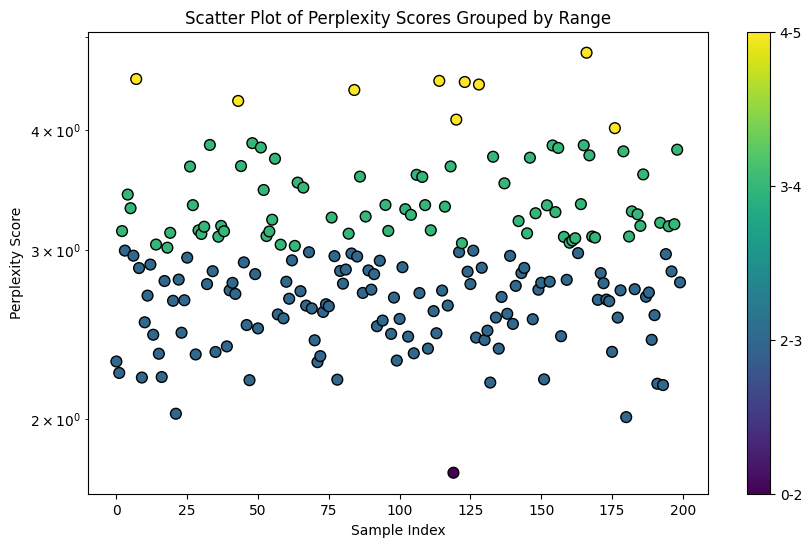

In [9]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from nltk.translate.bleu_score import sentence_bleu
from rouge import Rouge
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Load the dataset
train_df = pd.read_csv("medical_tc_test.csv")
texts = train_df["medical_abstract"][:200].tolist()

# Ensure tokenizer has a pad token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Create prompts from the first 50 words
prompts = [' '.join(str(text).split()[:50]) for text in texts]

def generate_long_text(model, tokenizer, prompt, max_length=300):    
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    output_ids = model.generate(input_ids, max_length=max_length, pad_token_id=tokenizer.eos_token_id)
    generated_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return generated_text

def calculate_perplexity(model, tokenizer, text):
    input_ids = tokenizer(text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        loss = outputs.loss
    return torch.exp(loss).item()

# Loop over prompts, generate text, and record perplexity scores
perplexity_scores = []
for i, prompt in enumerate(prompts):
    generated_text_str = generate_long_text(generator_model, tokenizer, prompt, max_length=300)
    perplexity = calculate_perplexity(generator_model, tokenizer, generated_text_str)
    perplexity_scores.append(perplexity)
    print(f"Sample {i}: Perplexity = {perplexity:.4f}")

# Save perplexity scores to a CSV file
df = pd.DataFrame({
    "Index": range(len(perplexity_scores)),
    "Perplexity": perplexity_scores
})
#df.to_csv("fi_lora_dp_med_gpt_perplexity_scores.csv", index=False)
#print("Perplexity scores saved to perplexity_scores.csv")

# Group perplexity scores into defined ranges.
# For this example, we group scores as: 0-20, 20-40, 40-60, 60-80, 80-100, and 100+
bins = [0,2,3,4,5,6,7,8,9,10,20, 40, 60, 80, 100, float('inf')]
labels = ["0-2", "2-3","3-4","4-5","5-6","6-7","7-8","8-9","9-10","10-20","20-40", "40-60", "60-80", "80-100", "100+"]
df["Perplexity Group"] = pd.cut(df["Perplexity"], bins=bins, labels=labels)

# Create a scatter plot of perplexity scores.
plt.figure(figsize=(10, 6))
# Color-code by perplexity group using categorical codes.
scatter = plt.scatter(df["Index"], df["Perplexity"], 
                      c=df["Perplexity Group"].cat.codes, cmap="viridis", s=60, edgecolor="k")
plt.xlabel("Sample Index")
plt.ylabel("Perplexity Score")
plt.title("Scatter Plot of Perplexity Scores Grouped by Range")
plt.yscale("log")  # Use logarithmic scale to better visualize a wide range of values.
# Create a colorbar with group labels.
cbar = plt.colorbar(scatter, ticks=range(len(labels)))
cbar.ax.set_yticklabels(labels)
#plt.savefig("fi_lora_dp_med_gpt_perplexity_scatter_plot.png", dpi=300, bbox_inches="tight")
plt.show()


In [1]:
!pip install panda

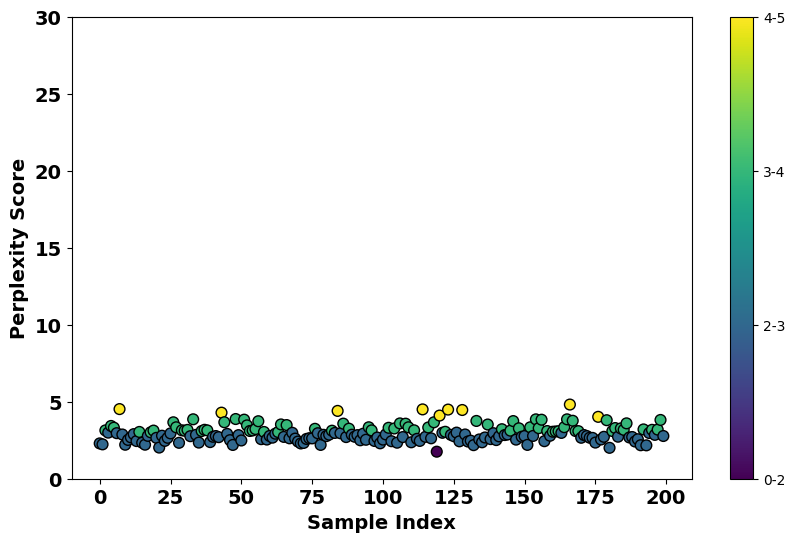

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("fi_lora_dp_med_gpt_perplexity_scores.csv")
# Group perplexity scores into defined ranges.
# For this example, we group scores as: 0-20, 20-40, 40-60, 60-80, 80-100, and 100+
bins = [0,2,3,4,5,6,7,8,9,10,20, 40, 60, 80, 100, float('inf')]
labels = ["0-2", "2-3","3-4","4-5","5-6","6-7","7-8","8-9","9-10","10-20","20-40", "40-60", "60-80", "80-100", "100+"]
df["Perplexity Group"] = pd.cut(df["Perplexity"], bins=bins, labels=labels)

# Create a scatter plot of perplexity scores.
plt.figure(figsize=(10, 6))
# Color-code by perplexity group using categorical codes.
scatter = plt.scatter(df["Index"], df["Perplexity"], 
                      c=df["Perplexity Group"].cat.codes, cmap="viridis", s=60, edgecolor="k")
plt.xlabel("Sample Index", fontweight="bold", fontsize=14)
plt.ylabel("Perplexity Score", fontweight="bold", fontsize=14)
plt.xticks(fontsize=14, fontweight='bold')  # Increase font size and make it bold
plt.yticks(fontsize=14, fontweight='bold')  # Increase font size and make it bold

plt.title("", fontweight="bold", fontsize=16)

# Fix y-axis range from 0 to 100
plt.ylim(0, 30)

# Create a colorbar with group labels.
cbar = plt.colorbar(scatter, ticks=range(len(labels)))
cbar.ax.set_yticklabels(labels)

plt.savefig("fi_lora_dp_med_gpt_perplexity_scatter_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
import numpy as np
np.mean(perplexity_scores)

2.956797602176666

In [ ]:
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from nltk.translate.bleu_score import sentence_bleu
from rouge import Rouge
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer
import re

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
train_df = pd.read_csv("medical_tc_test.csv")
texts = train_df["medical_abstract"][:200].tolist()
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
prompts = [' '.join(str(text).split()[:50]) for text in texts]

def generate_long_text(model, tokenizer, prompt, max_length=500, step_size=50):
    """
    Generates a long sequence of text by repeatedly feeding the model's output as input.
    """
    # Tokenize initial prompt and move to the desired device
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)    
    # Store generated tokens
    generated_text_ids = input_ids.clone()    
    # Generate until max length is reached
    while generated_text_ids.shape[-1] < max_length:
        outputs = model.generate(
            input_ids=generated_text_ids.to(device),
            max_length=generated_text_ids.shape[-1] + step_size,
            pad_token_id=tokenizer.pad_token_id,
            do_sample=True,
            top_k=90,
            temperature=0.8,
            top_p=0.95, num_beams=8, no_repeat_ngram_size=4,
            early_stopping=True, repetition_penalty=1.5, length_penalty=1.0,eos_token_id=tokenizer.eos_token_id
        )
        
        new_text_ids = outputs[:, generated_text_ids.shape[-1]:]
        generated_text_ids = torch.cat((generated_text_ids, new_text_ids), dim=-1)
        
        if tokenizer.eos_token_id in new_text_ids:
            break

    generated_text = tokenizer.decode(generated_text_ids[0], skip_special_tokens=True)
    generated_text = generated_text.replace("\n", "").replace("\r", "")
    #generated_text = re.sub(r'[^\w\s.,:]', '', generated_text)
    # Step 1: Remove non-ASCII characters
    generated_text = re.sub(r'[^\x00-\x7F]+', '', generated_text)
    # Step 2: Retain only letters, numbers, and basic punctuation
    #generated_text = re.sub(r'[^a-zA-Z0-9\s.,:;\'"-]', '', generated_text)
    # Step 3: Normalize spaces (remove extra spaces or newlines)
    #generated_text = re.sub(r'\s+', ' ', generated_text).strip()
    return generated_text
    
def calculate_perplexity(model, tokenizer, text):
    input_ids = tokenizer(text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        loss = outputs.loss                
    return torch.exp(loss).item()

def evaluate_generated_texts(reference_text, generated_text):
    reference_list = reference_text.split()
    generated_list = generated_text.split()
    bleu_score = sentence_bleu([reference_list], generated_list)
    rouge = Rouge()
    rouge_scores = rouge.get_scores(generated_text, reference_text)[0]
    P = rouge_scores['rouge-l']['p']
    R = rouge_scores['rouge-l']['r']
    F1 = rouge_scores['rouge-l']['f']
    vectorizer = CountVectorizer().fit_transform([reference_text, generated_text])
    vectors = vectorizer.toarray()
    cos_sim = cosine_similarity(vectors)[0][1]
    return bleu_score, rouge_scores, P, R, F1, cos_sim

total_bleu, total_rougeL, total_perplexity, total_sim = 0, 0, 0, 0
for i, prompt in enumerate(prompts):
    reference_text = texts[i]
    generated_text_str = generate_long_text(generator_model, tokenizer, prompt, max_length=500,step_size=50)
    print(f"Reference Text: {reference_text}")
    print(f"Generated Text: {generated_text_str}")
    bleu_score, rouge_scores, P, R, F1, cos_sim = evaluate_generated_texts(reference_text, generated_text_str)
    perplexity = calculate_perplexity(generator_model, tokenizer, generated_text_str)
    print(f"BLEU: {bleu_score}, ROUGE-L: {rouge_scores['rouge-l']}, Perplexity: {perplexity}, Cosine Similarity: {cos_sim:.4f}")    
    total_bleu += bleu_score
    total_rougeL += rouge_scores['rouge-l']['f']
    total_perplexity += perplexity
    total_sim += cos_sim
num_samples = len(prompts)
print("Average BLEU:", total_bleu / num_samples)
print("Average ROUGE-L:", total_rougeL / num_samples)
print("Average Perplexity:", total_perplexity / num_samples)
print("Average Cosine Similarity:", total_sim / num_samples)



Sample 0: Perplexity = 2.3456
Sample 1: Perplexity = 2.3832
Sample 2: Perplexity = 3.4541
Sample 3: Perplexity = 2.5203
Sample 4: Perplexity = 3.2759
Sample 5: Perplexity = 3.4306
Sample 6: Perplexity = 3.0845
Sample 7: Perplexity = 5.2679
Sample 8: Perplexity = 3.3506
Sample 9: Perplexity = 2.3592
Sample 10: Perplexity = 3.0744
Sample 11: Perplexity = 2.6723
Sample 12: Perplexity = 3.3226
Sample 13: Perplexity = 2.8980
Sample 14: Perplexity = 3.7236
Sample 15: Perplexity = 2.5182
Sample 16: Perplexity = 2.3527
Sample 17: Perplexity = 3.0885
Sample 18: Perplexity = 3.2637
Sample 19: Perplexity = 3.3630
Sample 20: Perplexity = 2.8014
Sample 21: Perplexity = 2.2518
Sample 22: Perplexity = 3.0484
Sample 23: Perplexity = 2.6808
Sample 24: Perplexity = 2.9615
Sample 25: Perplexity = 3.1893
Sample 26: Perplexity = 3.9504
Sample 27: Perplexity = 3.9804
Sample 28: Perplexity = 2.3746
Sample 29: Perplexity = 3.3483
Sample 30: Perplexity = 2.7389
Sample 31: Perplexity = 4.0203
Sample 32: Perplex

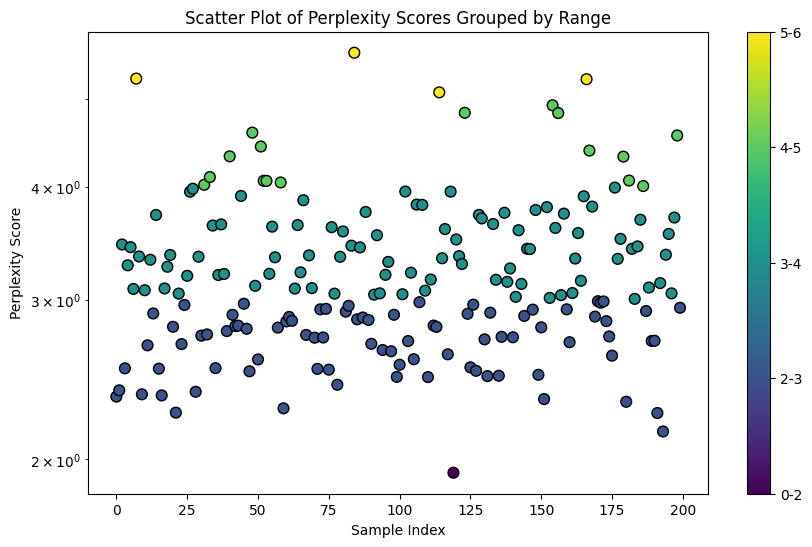

In [10]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from nltk.translate.bleu_score import sentence_bleu
from rouge import Rouge
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv("medical_tc_test.csv")
texts = train_df["medical_abstract"][:200].tolist()
# Ensure tokenizer has a pad token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Create prompts from the first 50 words
prompts = [' '.join(str(text).split()[:50]) for text in texts]

"""def generate_long_text(model, tokenizer, prompt, max_length=300):    
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    output_ids = model.generate(input_ids, max_length=max_length, num_return_sequences=1, pad_token_id=tokenizer.eos_token_id)
    generated_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return generated_text
"""
def generate_long_text(model, tokenizer, prompt, max_length=300, step_size=50):
    """
    Generates a long sequence of text by repeatedly feeding the model's output as input.
    """
    # Tokenize initial prompt and move to the desired device
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)    
    # Store generated tokens
    generated_text_ids = input_ids.clone()    
    # Generate until max length is reached
    while generated_text_ids.shape[-1] < max_length:
        outputs = model.generate(
            input_ids=generated_text_ids.to(device),
            max_length=generated_text_ids.shape[-1] + step_size,
            pad_token_id=tokenizer.pad_token_id,
            do_sample=True,
            top_k=90,
            temperature=0.8,
            top_p=0.95, num_beams=8, no_repeat_ngram_size=4,
            early_stopping=True, repetition_penalty=1.5, length_penalty=1.0,eos_token_id=tokenizer.eos_token_id
        )
        
        new_text_ids = outputs[:, generated_text_ids.shape[-1]:]
        generated_text_ids = torch.cat((generated_text_ids, new_text_ids), dim=-1)
        
        if tokenizer.eos_token_id in new_text_ids:
            break

    generated_text = tokenizer.decode(generated_text_ids[0], skip_special_tokens=True)
    generated_text = generated_text.replace("\n", "").replace("\r", "")
    #generated_text = re.sub(r'[^\w\s.,:]', '', generated_text)
    # Step 1: Remove non-ASCII characters
    generated_text = re.sub(r'[^\x00-\x7F]+', '', generated_text)
    # Step 2: Retain only letters, numbers, and basic punctuation
    #generated_text = re.sub(r'[^a-zA-Z0-9\s.,:;\'"-]', '', generated_text)
    # Step 3: Normalize spaces (remove extra spaces or newlines)
    #generated_text = re.sub(r'\s+', ' ', generated_text).strip()
    return generated_text

def calculate_perplexity(model, tokenizer, text):
    input_ids = tokenizer(text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        loss = outputs.loss
    return torch.exp(loss).item()

# Loop over prompts, generate text, and record perplexity scores
perplexity_scores = []
for i, prompt in enumerate(prompts):
    generated_text_str = generate_long_text(generator_model, tokenizer, prompt, max_length=300)
    perplexity = calculate_perplexity(generator_model, tokenizer, generated_text_str)
    perplexity_scores.append(perplexity)
    print(f"Sample {i}: Perplexity = {perplexity:.4f}")

# Save perplexity scores to a CSV file
df = pd.DataFrame({
    "Index": range(len(perplexity_scores)),
    "Perplexity": perplexity_scores
})
df.to_csv("fi_dp_lora_med_gpt_perplexity_scores.csv", index=False)
print("Perplexity scores saved to perplexity_scores.csv")

# Group perplexity scores into defined ranges.
# For this example, we group scores as: 0-20, 20-40, 40-60, 60-80, 80-100, and 100+
bins = [0,2,3,4,5,6,7,8,9,10,20, 40, 60, 80, 100, float('inf')]
labels = ["0-2", "2-3","3-4","4-5","5-6","6-7","7-8","8-9","9-10","10-20","20-40", "40-60", "60-80", "80-100", "100+"]
df["Perplexity Group"] = pd.cut(df["Perplexity"], bins=bins, labels=labels)

# Create a scatter plot of perplexity scores.
plt.figure(figsize=(10, 6))
# Color-code by perplexity group using categorical codes.
scatter = plt.scatter(df["Index"], df["Perplexity"], 
                      c=df["Perplexity Group"].cat.codes, cmap="viridis", s=60, edgecolor="k")
plt.xlabel("Sample Index")
plt.ylabel("Perplexity Score")
plt.title("Scatter Plot of Perplexity Scores Grouped by Range")
plt.yscale("log")  # Use logarithmic scale to better visualize a wide range of values.
# Create a colorbar with group labels.
cbar = plt.colorbar(scatter, ticks=range(len(labels)))
cbar.ax.set_yticklabels(labels)
plt.savefig("fi_dp_lora_med_gpt_perplexity_scatter_plot.png", dpi=300, bbox_inches="tight")
plt.show()


In [14]:
np.mean(perplexity_scores)



3.2082558375597

In [ ]:
torch.cuda.empty_cache()

[LightGBM] [Info] Number of positive: 404, number of negative: 396
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000114 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 866
[LightGBM] [Info] Number of data points in the train set: 800, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga

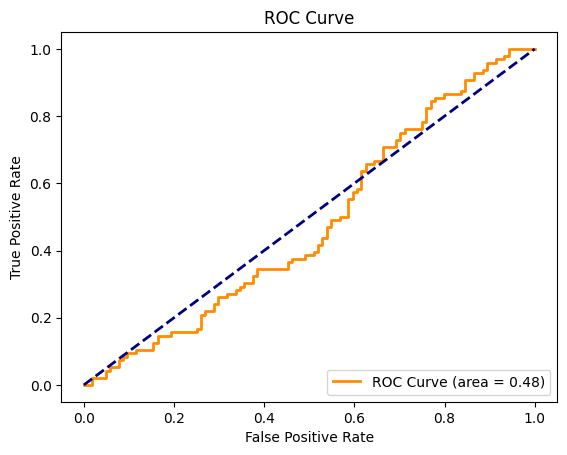

In [11]:
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from lightgbm import LGBMClassifier
from scipy.stats import entropy
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Set up device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Load your datasets
train_df = pd.read_csv("medical_tc_train.csv")  # Adjust file name if necessary
test_df = pd.read_csv("medical_tc_test.csv")    # Adjust file name if necessary

# Extract texts
train_texts = train_df["medical_abstract"][:500].tolist()  # Adjust column name if needed
test_texts = test_df["medical_abstract"][:500].tolist()    # Adjust column name if needed

# Ensure tokenizer has a pad token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def generate_long_text(model, tokenizer, prompt, max_length=300):    
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    output_ids = model.generate(input_ids, max_length=max_length, pad_token_id=tokenizer.eos_token_id)
    generated_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return generated_text


# Function to calculate perplexity
def calculate_perplexity(model, tokenizer, text, device):    
    input_ids = tokenizer(text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        loss = outputs.loss
    ppl = torch.exp(loss).item()
    #print(ppl)
    return ppl

# Function to calculate prediction confidence
def calculate_prediction_confidence(model, tokenizer, text, device):
    input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids)
        probabilities = torch.softmax(outputs.logits, dim=-1)
        return probabilities.max().item()

# Function to calculate entropy
def calculate_entropy(model, tokenizer, text, device):
    input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids)
        probabilities = torch.softmax(outputs.logits, dim=-1)
        return entropy(probabilities.cpu().numpy().flatten())

# Function to calculate feature representation distance
def calculate_feature_representation_distance(model, tokenizer, text, centroid, device):
    input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
    with torch.no_grad():
        embeddings = model.transformer.wte(input_ids).mean(dim=1).cpu().numpy()
    return np.linalg.norm(embeddings - centroid)

# Calculate centroid for training set embeddings
def calculate_centroid(model, tokenizer, texts, device):
    embeddings = []
    for text in texts:
        input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
        with torch.no_grad():
            embedding = model.transformer.wte(input_ids).mean(dim=1).cpu().numpy()
        embeddings.append(embedding)
    return np.mean(embeddings, axis=0)

# Calculate centroid for training texts
train_centroid = calculate_centroid(generator_model, tokenizer, train_texts, device)

# Calculate features for training and test texts
def calculate_features(model, tokenizer, texts, centroid, device):
    perplexities, confidences, entropies, frd_distances = [], [], [], []
    for text in texts:
        prompt = ' '.join(str(text).split()[:50])
        #print(prompt)
        text = generate_long_text(model, tokenizer, prompt, max_length=300)
        perplexities.append(calculate_perplexity(model, tokenizer, text, device))
        confidences.append(calculate_prediction_confidence(model, tokenizer, text, device))
        entropies.append(calculate_entropy(model, tokenizer, text, device))
        frd_distances.append(calculate_feature_representation_distance(model, tokenizer, text, centroid, device))
    return perplexities, confidences, entropies, frd_distances

train_features = calculate_features(generator_model, tokenizer, train_texts, train_centroid, device)
test_features = calculate_features(generator_model, tokenizer, test_texts, train_centroid, device)

# Combine features and labels
train_labels = [1] * len(train_texts)  # Members
test_labels = [0] * len(test_texts)    # Non-members

combined_features = np.vstack((
    np.column_stack(train_features),
    np.column_stack(test_features)
))
combined_labels = np.array(train_labels + test_labels)
# Normalize features
scaler = MinMaxScaler()
normalized_features = scaler.fit_transform(combined_features)

# Split data for training the attack model
X_train, X_test, y_train, y_test = train_test_split(normalized_features, combined_labels, test_size=0.2, random_state=42)

# Train LightGBM attack model
clf = LGBMClassifier(class_weight="balanced", learning_rate=0.1, n_estimators=100)
clf.fit(X_train, y_train)

# Evaluate the attack model
y_pred = clf.predict(X_test)
y_pred_prob = clf.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_prob)
print(f"ROC-AUC: {roc_auc:.2f}")

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC Curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.savefig("fi_lora_dp_high_med_txt_gen_roc_plots.jpg", dpi=300, bbox_inches="tight")

plt.show()


In [10]:
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from lightgbm import LGBMClassifier
from scipy.stats import entropy
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import csv

# Set up device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Ensure tokenizer has a pad token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load datasets
train_df = pd.read_csv("medical_tc_train.csv")  # Adjust file name if necessary
test_df = pd.read_csv("medical_tc_test.csv")    # Adjust file name if necessary

train_texts = train_df["medical_abstract"][:200].tolist()
test_texts = test_df["medical_abstract"][:200].tolist()

def generate_long_text(model, tokenizer, prompt, max_length=300):    
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    output_ids = model.generate(input_ids, max_length=max_length, pad_token_id=tokenizer.eos_token_id)
    generated_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return generated_text

# Function to calculate perplexity
def calculate_perplexity(model, tokenizer, text, device):
    input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        loss = outputs.loss
    return torch.exp(loss).item()

# Function to calculate prediction confidence
def calculate_prediction_confidence(model, tokenizer, text, device):
    input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids)
        probabilities = torch.softmax(outputs.logits, dim=-1)
        return probabilities.max().item()

# Function to calculate entropy
def calculate_entropy(model, tokenizer, text, device):
    input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids)
        probabilities = torch.softmax(outputs.logits, dim=-1)
        return entropy(probabilities.cpu().numpy().flatten())

# Function to calculate feature representation distance
def calculate_feature_representation_distance(model, tokenizer, text, centroid, device):
    input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
    with torch.no_grad():
        embeddings = model.transformer.wte(input_ids).mean(dim=1).cpu().numpy()
    return np.linalg.norm(embeddings - centroid)

# Calculate centroid for training set embeddings
def calculate_centroid(model, tokenizer, texts, device):
    embeddings = []
    for text in texts:
        input_ids = tokenizer(text, return_tensors="pt", padding=True, truncation=True).input_ids.to(device)
        with torch.no_grad():
            embedding = model.transformer.wte(input_ids).mean(dim=1).cpu().numpy()
        embeddings.append(embedding)
    return np.mean(embeddings, axis=0)

# Calculate centroid for training texts
train_centroid = calculate_centroid(generator_model, tokenizer, train_texts, device)
test_centroid = calculate_centroid(generator_model, tokenizer, test_texts, device)

# Calculate features for training and test texts
def calculate_features(model, tokenizer, texts, centroid, device):
    perplexities, confidences, entropies, frd_distances = [], [], [], []
    for text in texts:
        prompt = ' '.join(str(text).split()[:50])
        #print(prompt)
        text = generate_long_text(model, tokenizer, prompt, max_length=300)
        perplexities.append(calculate_perplexity(model, tokenizer, text, device))
        confidences.append(calculate_prediction_confidence(model, tokenizer, text, device))
        entropies.append(calculate_entropy(model, tokenizer, text, device))
        frd_distances.append(calculate_feature_representation_distance(model, tokenizer, text, centroid, device))
    return perplexities, confidences, entropies, frd_distances

# Open CSV file to store results
csv_filename = "fi_lora_dp_high_med_txt_gen_attack_model_results_new.csv"
with open(csv_filename, mode="w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["Run", "Precision", "Recall", "F1-Score", "ROC-AUC"])

    for run in range(1, 11):  # Run 10 times
        print(f"Run {run}...")
        train_features = calculate_features(generator_model, tokenizer, train_texts, train_centroid, device)
        test_features = calculate_features(generator_model, tokenizer, test_texts, test_centroid, device)
    
        # Combine features and labels
        train_labels = [1] * len(train_texts)  # Members
        test_labels = [0] * len(test_texts)    # Non-members
    
        combined_features = np.vstack((
            np.column_stack(train_features),
            np.column_stack(test_features)
        ))
        combined_labels = np.array(train_labels + test_labels)
        # Normalize features
        scaler = MinMaxScaler()
        normalized_features = scaler.fit_transform(combined_features)      
        
        # Split data for training the attack model
        X_train, X_test, y_train, y_test = train_test_split(normalized_features, combined_labels, test_size=0.2, random_state=42 + run)

        # Train LightGBM attack model
        clf = LGBMClassifier(class_weight="balanced", learning_rate=0.1, n_estimators=100)
        clf.fit(X_train, y_train)

        # Evaluate the attack model
        y_pred = clf.predict(X_test)
        y_pred_prob = clf.predict_proba(X_test)[:, 1]

        report = classification_report(y_test, y_pred, output_dict=True)
        precision = report["macro avg"]["precision"]
        recall = report["macro avg"]["recall"]
        f1_score = report["macro avg"]["f1-score"]
        roc_auc = roc_auc_score(y_test, y_pred_prob)

        print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1_score:.4f}, ROC-AUC: {roc_auc:.4f}")

        # Save to CSV
        writer.writerow([run, precision, recall, f1_score, roc_auc])

print(f"Results saved to {csv_filename}")


Run 1...
[LightGBM] [Info] Number of positive: 165, number of negative: 155
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000071 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 427
[LightGBM] [Info] Number of data points in the train set: 320, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [9]:
!pip install seaborn

In [1]:
import math
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, auc, roc_auc_score, roc_curve, classification_report
from transformers import AutoTokenizer, AutoModelForCausalLM
from tqdm import tqdm

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
train_csv = "medical_tc_train.csv"
test_csv  = "medical_tc_test.csv"
text_column = "medical_abstract"
max_samples = 200   # Limit for speed; set None for all
batch_size = 4
max_length = 300
k_percent = 20.0    # k% from algorithm
threshold_epsilon = None  # Will be tuned on training set

model_name = "gpt2-large"
tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(model_name)
def load_model(model,filename='fi_lora_dp_high_med_txt_gen.pth'):
    # Load the state_dict from the saved file
    checkpoint = torch.load(filename)
    epoch = checkpoint['epoch']
    model.resize_token_embeddings(len(tokenizer))
    model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    print(f"Model loaded from {filename}")
    return model, epoch
model, start_epoch = load_model(model)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
model.to(device)
model.eval()

train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

train_texts = train_df["medical_abstract"].tolist()
test_texts = test_df["medical_abstract"].tolist()

# Use first 200 training samples for evaluation
train_eval_texts = train_texts[:500]
test_eval_texts = test_texts[:500]

def generate_long_text(eval_texts):
    # Build non-member texts by prompting with first 50 tokens
    prompted_texts = []
    gen_texts = []
    for text in eval_texts:
        enc = tokenizer(text, truncation=True, max_length=50, return_tensors="pt").to(device)
        prompt = tokenizer.decode(enc.input_ids[0], skip_special_tokens=True)
        prompted_texts.append(prompt)
    
        # Generate continuation
        out = model.generate(
            enc.input_ids,
            max_length=300,          # continuation length
            do_sample=True,
            top_k=50,
            top_p=0.95,
            temperature=0.8,
            pad_token_id=tokenizer.eos_token_id
        )
        gen_text = tokenizer.decode(out[0], skip_special_tokens=True)
        gen_texts.append(gen_text)
        
    #print("Sample prompt:\n", prompted_texts[0])
    #print("Generated continuation:\n", gen_texts[0])
    return gen_texts


@torch.no_grad()
def seq_nll_list(model, tokenizer, txt, device, max_length=300, batch_size=4):
    """
    Returns: list of 1D numpy arrays (per-token NLL) for each sequence
    """
    enc = tokenizer(txt, return_tensors="pt", padding=True,
                        truncation=True, max_length=max_length).to(device)
    input_ids = enc.input_ids
        
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
    loss, logits = outputs[:2]
    # Apply softmax to the logits to get probabilities
    probabilities = torch.nn.functional.log_softmax(logits, dim=-1)
    # probabilities = torch.nn.functional.softmax(logits, dim=-1)
    all_prob = []
    input_ids_processed = input_ids[0][1:]
    for i, token_id in enumerate(input_ids_processed):
        probability = probabilities[0, i, token_id].item()
        all_prob.append(probability)
    return torch.exp(loss).item(), all_prob, loss.item()

def min_k_percent_nll_score(all_prob, k_percent): 
    k_length = int(len(all_prob)*0.2)    
    topk_prob = np.sort(all_prob)[:k_length]
    #print(len(topk_prob))
    return -np.mean(topk_prob).item()
member_scores = []
nonmember_scores = []
train_gen_texts = generate_long_text(train_eval_texts)
test_gen_texts = generate_long_text(test_eval_texts)

for text in train_gen_texts:
    _, all_prob_members, _ = seq_nll_list(model, tokenizer, text, device, max_length, batch_size)
    member_scores.append(min_k_percent_nll_score(all_prob_members, k_percent))
    
for text in test_gen_texts:
    _, all_prob_nonmembers, _ = seq_nll_list(model, tokenizer, text, device, max_length, batch_size)
    nonmember_scores.append(min_k_percent_nll_score(all_prob_nonmembers, k_percent))
    
scores = np.concatenate([member_scores, nonmember_scores])
labels = np.concatenate([np.ones(len(member_scores)), np.zeros(len(nonmember_scores))])
print(scores)
fpr, tpr, thresholds = roc_curve(labels, -scores)
roc_auc = auc(fpr, tpr)
f1 = np.max(1-(fpr+(1-tpr))/2)

print("\n=== Min-k% Probability MIA Results ===")
print(f"k%: {k_percent}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"F1: {f1:.4f}")

C:\Users\my pc\AppData\Local\Temp\ipykernel_2608\289894183.py:26: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(filename)


Model loaded from fi_lora_dp_high_med_txt_gen.pth


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


[4.9936901  4.24141671 4.42385724 4.70981303 3.88450781 4.52066923
 4.23967084 3.95672313 6.2887469  6.41750609 5.35587322 4.63888335
 4.53155278 5.19033251 4.64640053 4.87673195 4.39583537 4.30679148
 5.78564396 4.70877417 4.94631328 5.08889306 4.76436848 4.44074294
 4.74723944 5.07322381 3.64621062 4.55046958 4.52237263 4.9506691
 4.83210415 4.91271568 5.29086263 4.80554824 4.06981967 4.87263266
 4.74557259 4.58198351 5.01013676 4.94899514 4.73221211 4.76961828
 4.33354028 5.15062408 4.33708296 4.65692044 4.88506695 5.98139645
 4.54204538 4.48663577 4.77050882 5.37002626 4.30300654 5.39374509
 4.02727283 4.23162488 4.36116457 5.21339858 4.60369462 4.88590186
 4.3879535  4.72900176 4.46930423 4.41864714 4.79138401 5.24805881
 5.85282356 4.39121605 3.48520034 4.187208   4.51942593 4.20379775
 4.55982546 3.94739258 4.64346998 4.21344322 5.41250171 4.46804577
 4.80811048 6.15043524 4.72119311 4.09170068 4.2618706  4.31685947
 4.80736183 4.29340673 4.64140653 4.67171361 4.61557179 5.07921

In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import tqdm

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM

from sklearn.metrics import roc_curve, auc, accuracy_score

# ----------------------------
# Settings
# ----------------------------
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

train_csv = "medical_tc_train.csv"
test_csv  = "medical_tc_test.csv"
NUM_NEIGHBORS = 1                            # number of neighbors to generate per text
MAX_GEN_LEN = 64                             # max length for neighbor generation

# ----------------------------
# Load model and tokenizer
# ----------------------------
model_name = "gpt2-large"
tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(model_name)
def load_model(model,filename='fi_lora_dp_high_med_txt_gen.pth'):
    # Load the state_dict from the saved file
    checkpoint = torch.load(filename)
    epoch = checkpoint['epoch']
    model.resize_token_embeddings(len(tokenizer))
    model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    print(f"Model loaded from {filename}")
    return model, epoch
model, start_epoch = load_model(model)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
model.to(device)
model.eval()

train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

train_texts = train_df["medical_abstract"][:500].tolist()
test_texts = test_df["medical_abstract"][:500].tolist()

# ----------------------------
# Inference: log-likelihood
# ----------------------------
def compute_log_likelihood(text, model, tokenizer):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512).to(device)
    with torch.no_grad():
        outputs = model(**inputs, labels=inputs["input_ids"])
        loss = outputs.loss
    return -loss.item()   # higher = more likely under model

# ----------------------------
# Generate neighbor texts
# ----------------------------
def generate_neighbors(text, model, tokenizer, num_neighbors=NUM_NEIGHBORS, max_length=MAX_GEN_LEN):
    enc = tokenizer(text, truncation=True, max_length=50, return_tensors="pt").to(device)
    neighbors = []
    with torch.no_grad():
        for _ in range(num_neighbors):
            output = model.generate(
                enc.input_ids,
                max_length=128,
                do_sample=True,
                top_k=50,
                top_p=0.95,
                temperature=0.8,
                pad_token_id=tokenizer.eos_token_id
            )
            gen_text = tokenizer.decode(output[0], skip_special_tokens=True)
            neighbors.append(gen_text)
    return neighbors

# ----------------------------
# Compute neighbor scores
# ----------------------------
member_scores = []
for i, text in enumerate(tqdm(train_texts, desc="Samples")):
    ll = compute_log_likelihood(text, model, tokenizer)
    neighbors = generate_neighbors(text, model, tokenizer, NUM_NEIGHBORS, MAX_GEN_LEN)
    ll_neighbors = [compute_log_likelihood(nb, model, tokenizer) for nb in neighbors]
    score = ll - np.mean(ll_neighbors)
    member_scores.append(score)
nonmember_scores = []
for i, text in enumerate(tqdm(test_texts, desc="Samples")):
    ll = compute_log_likelihood(text, model, tokenizer)
    neighbors = generate_neighbors(text, model, tokenizer, NUM_NEIGHBORS, MAX_GEN_LEN)
    ll_neighbors = [compute_log_likelihood(nb, model, tokenizer) for nb in neighbors]
    score = ll - np.mean(ll_neighbors)
    nonmember_scores.append(score)
scores = np.concatenate([member_scores, nonmember_scores])
labels = np.concatenate([np.ones(len(member_scores)), np.zeros(len(nonmember_scores))])
# ----------------------------
# Compute Metrics
# ----------------------------
fpr, tpr, thresholds = roc_curve(labels, scores)
auroc = auc(fpr, tpr)
f1 = np.max(1-(fpr+(1-tpr))/2)
print("=== Results ===")
print(f"AUROC: {auroc:.3f}")
print(f"F1: {f1:.3f}")


C:\Users\my pc\AppData\Local\Temp\ipykernel_9040\4269128954.py:32: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(filename)


Model loaded from fi_lora_dp_high_med_txt_gen.pth


Samples: 100%|██████████| 500/500 [06:33<00:00,  1.27it/s]

=== Results ===
AUROC: 0.506
F1: 0.521


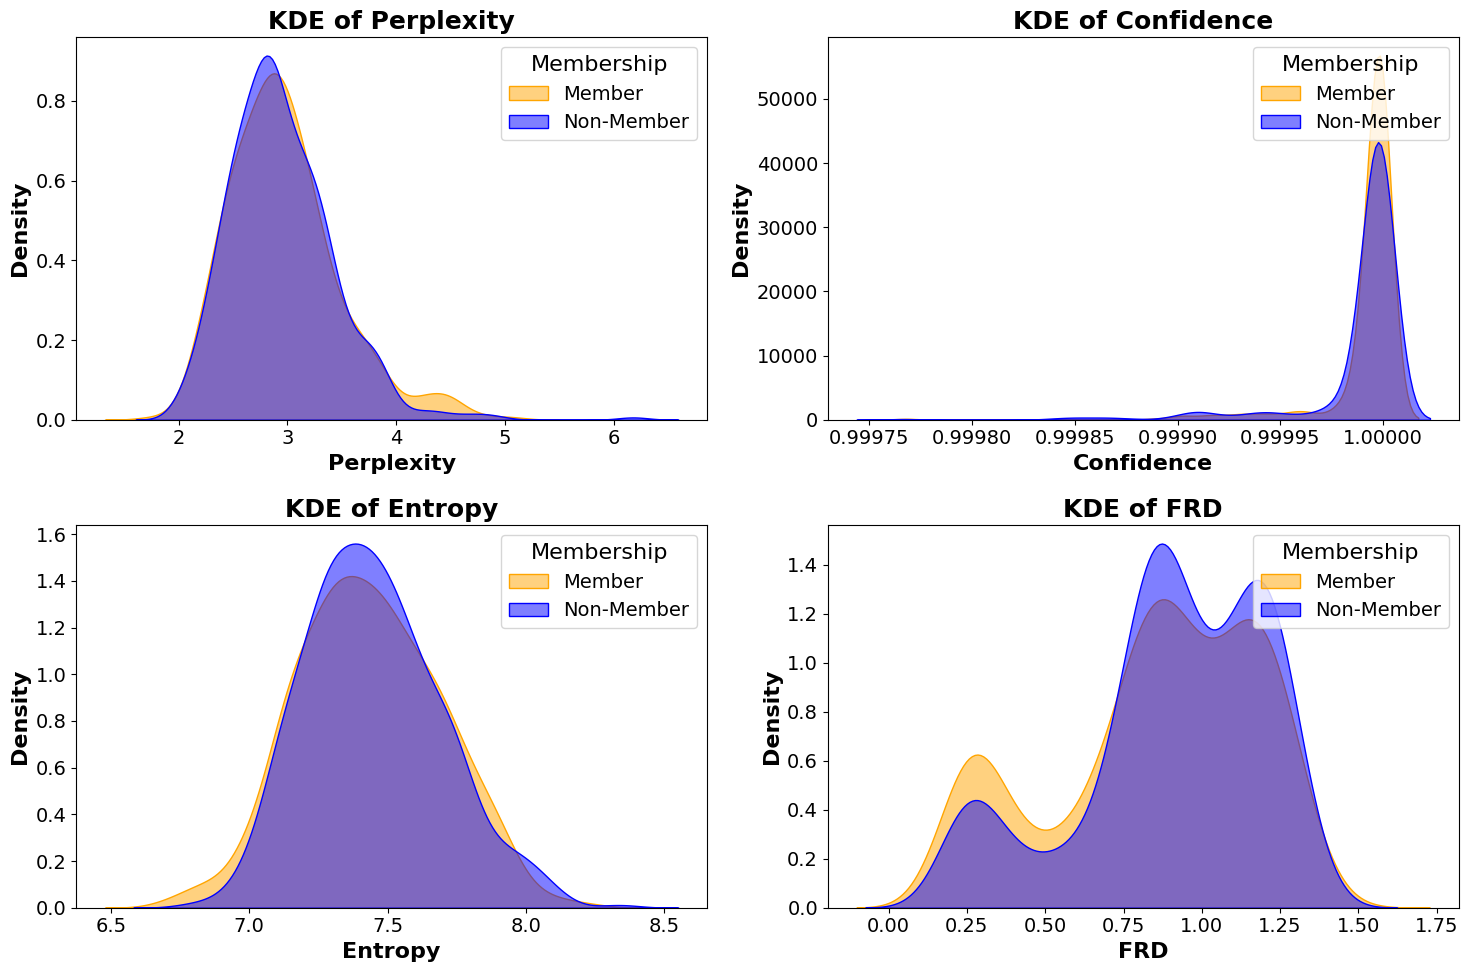

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Extract individual feature arrays
train_perplexities, train_confidences, train_entropies, train_frd = train_features
test_perplexities, test_confidences, test_entropies, test_frd = test_features

# Combine train and test features for each category
perplexities = np.concatenate([train_perplexities, test_perplexities])
confidences = np.concatenate([train_confidences, test_confidences])
entropies = np.concatenate([train_entropies, test_entropies])
frd_distances = np.concatenate([train_frd, test_frd])

# Combine member (1) and non-member (0) labels
labels = np.concatenate([[1] * len(train_perplexities), [0] * len(test_perplexities)])

df = pd.DataFrame({
    "Perplexity": perplexities,
    "Confidence": confidences,
    "Entropy": entropies,
    "FRD": frd_distances,
    "Membership": labels
})

# Convert Membership to categorical for seaborn
df["Membership"] = df["Membership"].map({1: "Member", 0: "Non-Member"})
# Set global font settings
plt.rcParams.update({
    "font.size": 16,      # Increase font size
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "legend.title_fontsize": 16,
    "axes.labelsize": 16,
})
# Plot KDE for each feature
features = ["Perplexity", "Confidence", "Entropy", "FRD"]
plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.kdeplot(data=df, x=feature, hue="Membership", fill=True, common_norm=False, alpha=0.5, palette={"Member": "blue", "Non-Member": "orange"} )
    plt.title(f"KDE of {feature}",fontweight="bold",fontsize=18)
    plt.xlabel(feature,fontweight="bold",fontsize=16)
    plt.ylabel("Density",fontweight="bold",fontsize=16)
    plt.legend(
        title="Membership", 
        loc="upper right", 
        labels=["Member", "Non-Member"], 
        frameon=True
    )

plt.tight_layout()

plt.savefig("fi_lora_dp_high_med_txt_gen_kde_plots.jpg", dpi=300, bbox_inches="tight")

plt.show()


In [61]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model.to(device)
model.eval()
PROMPT_LENGTH=50
def tokenize_text(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True)
    return inputs

def decode_tokens(tokens):
    return [tokenizer.decode([token]) for token in tokens]

def compute_shap_values(model, tokenizer, text, max_length=300):
    inputs = tokenize_text(text)
    input_ids = inputs["input_ids"].to(device)  # Extract the 'input_ids' tensor
    #print(f"INPUT IDS: {input_ids} and SHAPE: {input_ids.shape}")
    # Generate synthetic texts with prompts (subset of input_ids)
    prompts = input_ids[:, :PROMPT_LENGTH]  # Slice to use only the first 50 tokens as the prompt
    generated_ids = model.generate(input_ids=prompts,max_length=300+10,do_sample=True,top_k=90,temperature=0.8,top_p=0.95, num_beams=8, 
                                       no_repeat_ngram_size=4,early_stopping=True, repetition_penalty=1.5, length_penalty=1.0,
                                       pad_token_id=tokenizer.pad_token_id,eos_token_id=tokenizer.eos_token_id)
    #input_texts = tokenizer.batch_decode(input_ids, skip_special_tokens=True)      
    tokens = tokenizer.tokenize(text)
    input_texts_np = np.array(tokens).reshape(-1, 1)
    #print(f"INPUT IDS: {input_texts_np} and SHAPE: {input_texts_np.shape}")
    explainer = shap.KernelExplainer(
           lambda texts: model(**tokenizer(list(texts.flatten()), return_tensors="pt", 
                                                      padding=True, truncation=True).to(device)).logits[:, -1, :].cpu().detach().numpy(), input_texts_np  # Baseline as 2D NumPy array
    )
    #shap_values = explainer.shap_values(input_texts_np, nsamples=100)
    #token_importances = np.mean(np.abs(shap_values), axis=-1).flatten()
    #print(f"TOKEN IMP: {token_importances}")
    shap_texts = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)   
    print(shap_texts[0])
    gen_inputs = tokenize_text(shap_texts[0])
    gen_input_ids = gen_inputs["input_ids"].to(device)  # Extract the 'input_ids' tensor    
    gen_tokens = tokenizer.tokenize(shap_texts[0])
    shap_texts_np = np.array(gen_tokens).reshape(-1, 1) 
    shap_values = explainer.shap_values(shap_texts_np, nsamples=100)    
    return shap_texts[0], shap_values
text = "Obstructive sleep apnea following topical oropharyngeal anesthesia in loud snorers. Previous studies support the presence of an upper airway reflex mechanism that contributes to the maintenance of upper airway patency during sleep. We investigated the possibility that interference with this reflex mechanism contributes to the development of obstructive sleep apnea. Eight otherwise asymptomatic snorers (seven male and one female), age 39 +/- 5.3 yr (mean +/- SEM), underwent overnight sleep studies on three successive nights. An acclimatization night was followed by two study nights randomly assigned to control (C) and oropharyngeal anesthesia (OPA). On the OPA night topical anesthesia was induced using 10% lidocaine spray and 0.25% bupivacaine gargle. A saline placebo was used on night C. All subjects slept well on both study nights (mean sleep duration was 6.2 h on both study nights), and sleep stage distribution was similar on both nights. Obstructive apneas and hypopneas (OAH) rose from 114 +/- 43 during C to 170 +/- 49 during OPA (p less than 0.02). Central apneas and hypopneas (CAH) were unchanged between the two nights (8 +/- 4.9 versus 7 +/- 3). The duration of OAH was similar on both study nights (20 +/- 1.9 s during C versus 20 +/- 1.5 s during OPA). The frequency of movement arousals terminating OAH tended to be higher during OPA (7 +/- 2.9/h) than during C (3 +/- 0.7); P = NS. The frequency of oxyhemoglobin desaturations was also higher during OPA (5 +/- 2.1/h) than during C (3 +/- 1.4), p less than 0.07."
# Compute SHAP values for tokens
text, shap_values = compute_shap_values(model, tokenizer, text)
#print(f"Raw SHAP values:{shap_values} SHAPE:{shap_values.shape}")
# Extract token importance
#token_importances = np.mean(np.abs(shap_values), axis=-1).flatten()
token_importances = np.mean(shap_values, axis=-1).flatten()
# Decode tokens
tokens = decode_tokens(tokenizer(text, return_tensors="pt")["input_ids"][0].tolist())
print(len(tokens))
print(len(token_importances))
#for i, (token, importance) in enumerate(zip(tokens, token_importances)):
#    #if i < 10:  # Limit to the first 10 for debug purposes
#    print(f"I:  {i} Token: {token} | SHAP Value: {importance}")




Using 379 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


Obstructive sleep apnea following topical oropharyngeal anesthesia in loud snorers. Previous studies support the presence of an upper airway reflex mechanism that contributes to the maintenance of upper airway patency during sleep. We investigated the possibility that erythrocyte sedimentation rate (ESR) and erythropoietin (EPO) levels were related to the severity of snoring in a population-based case-control study. ESR and EPO levels were measured at baseline and at 6, 12, 24, 36, 48, and 72 h after the onset of snoring. There was a significant positive correlation between snoring severity and ESR (r = 0.66, P < 0.001), but there was no significant correlation between ERO and EPO (r = −0.00, P = 0.862). There was also a significant negative correlation between the number of snoring episodes and the number of ESRs (r = -0.16, P < 1.000), but this did not reach statistical significance (P = 0.904). There was no significant difference in the number of EPO levels between those who snored 

  0%|          | 0/310 [00:00<?, ?it/s]

310
310


In [68]:
# Initialize empty lists for tokens and SHAP values
tokens_list = []
shap_values_list = []

# Iterate through the tokens and their corresponding SHAP values
for i, (token, importance) in enumerate(zip(tokens, token_importances)):
    # Add token and importance to the lists
    tokens_list.append(token)
    shap_values_list.append(importance)

# Create a list of tuples (token, shap_value) and sort by shap_value in descending order
sorted_tokens_shap = sorted(zip(tokens_list, shap_values_list), key=lambda x: abs(x[1]), reverse=True)

# Get the top 50 tokens and SHAP values
top_50_tokens, top_50_shap_values = zip(*sorted_tokens_shap[:150])

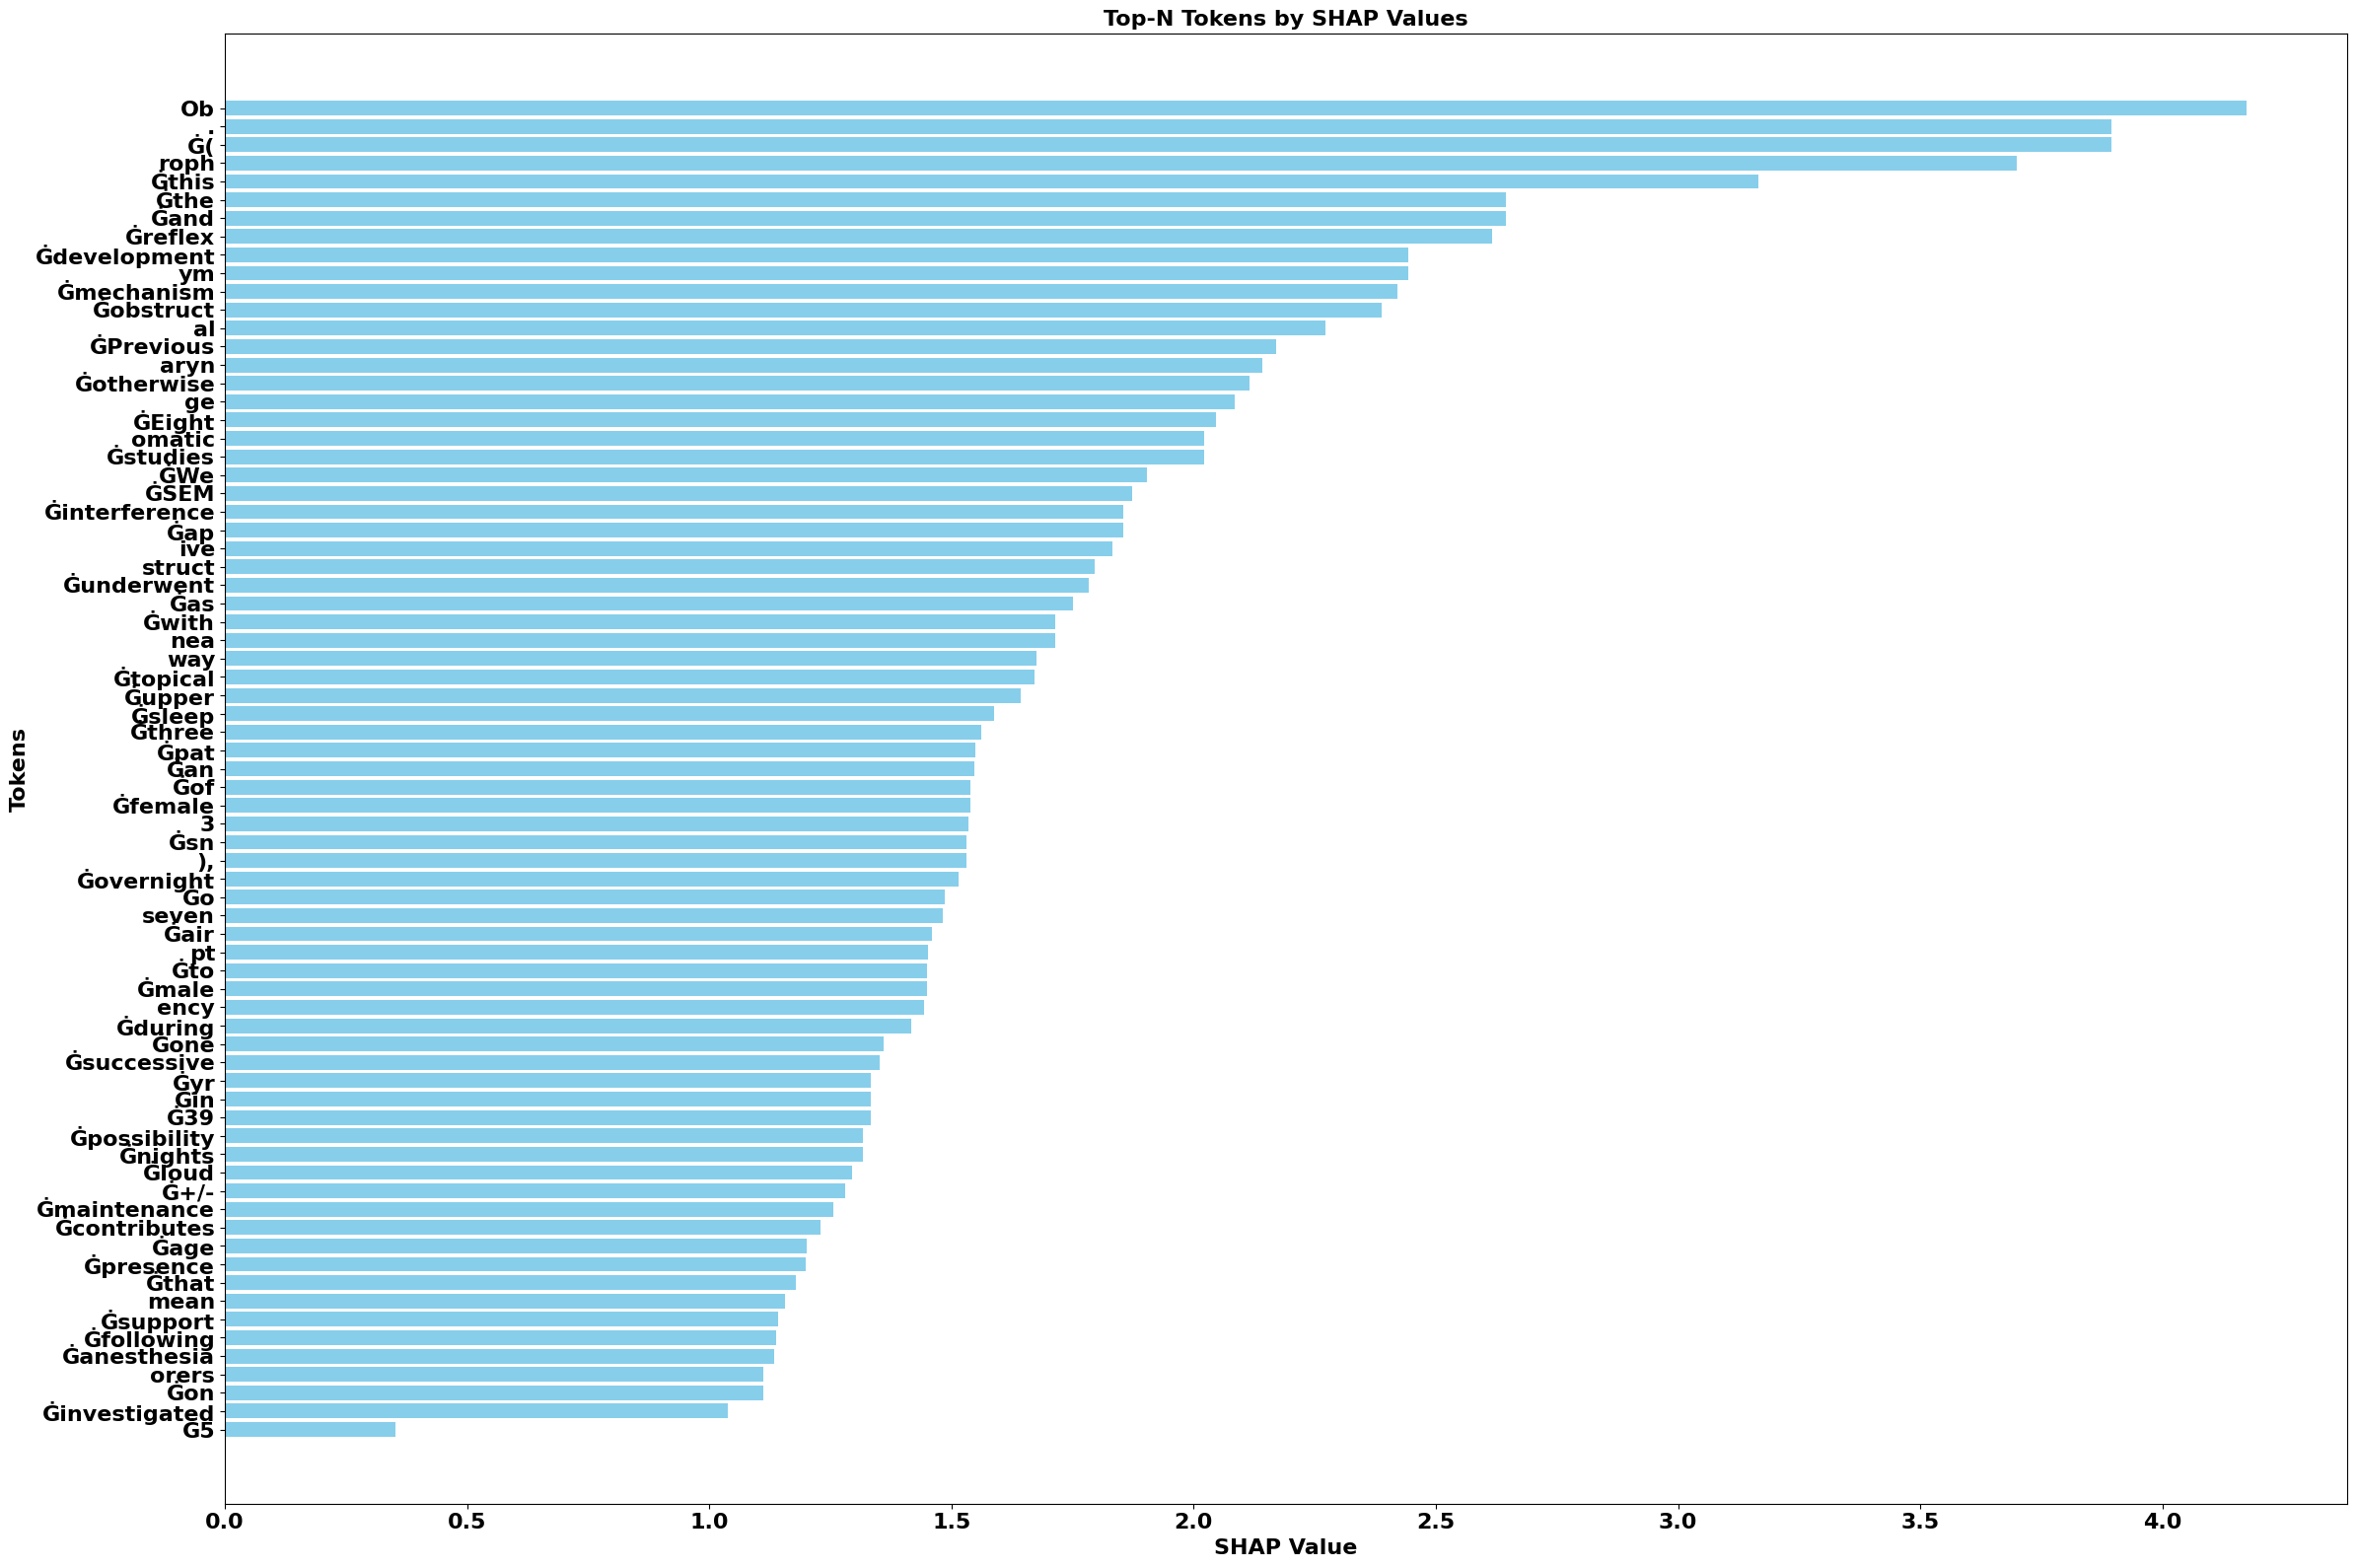

In [89]:
import matplotlib.pyplot as plt
import numpy as np

# Plot the bar chart
plt.figure(figsize=(24, 16))
plt.barh(top_50_tokens, top_50_shap_values, color="skyblue")
plt.xlabel("SHAP Value", fontsize=16, fontweight='bold')
plt.ylabel("Tokens", fontsize=16, fontweight='bold')
plt.xticks(fontsize=16, fontweight='bold')  # Set font size and make them bold
plt.yticks(fontsize=16, fontweight='bold')  # Set font size and make them bold
plt.title("Top-N Tokens by SHAP Values", fontsize=16, fontweight='bold')
plt.gca().invert_yaxis()  # Invert y-axis to display highest SHAP value at the top
plt.tight_layout()
plt.savefig('fi_shap_plot.jpg')
plt.show()


`GPT2SdpaAttention` is used but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


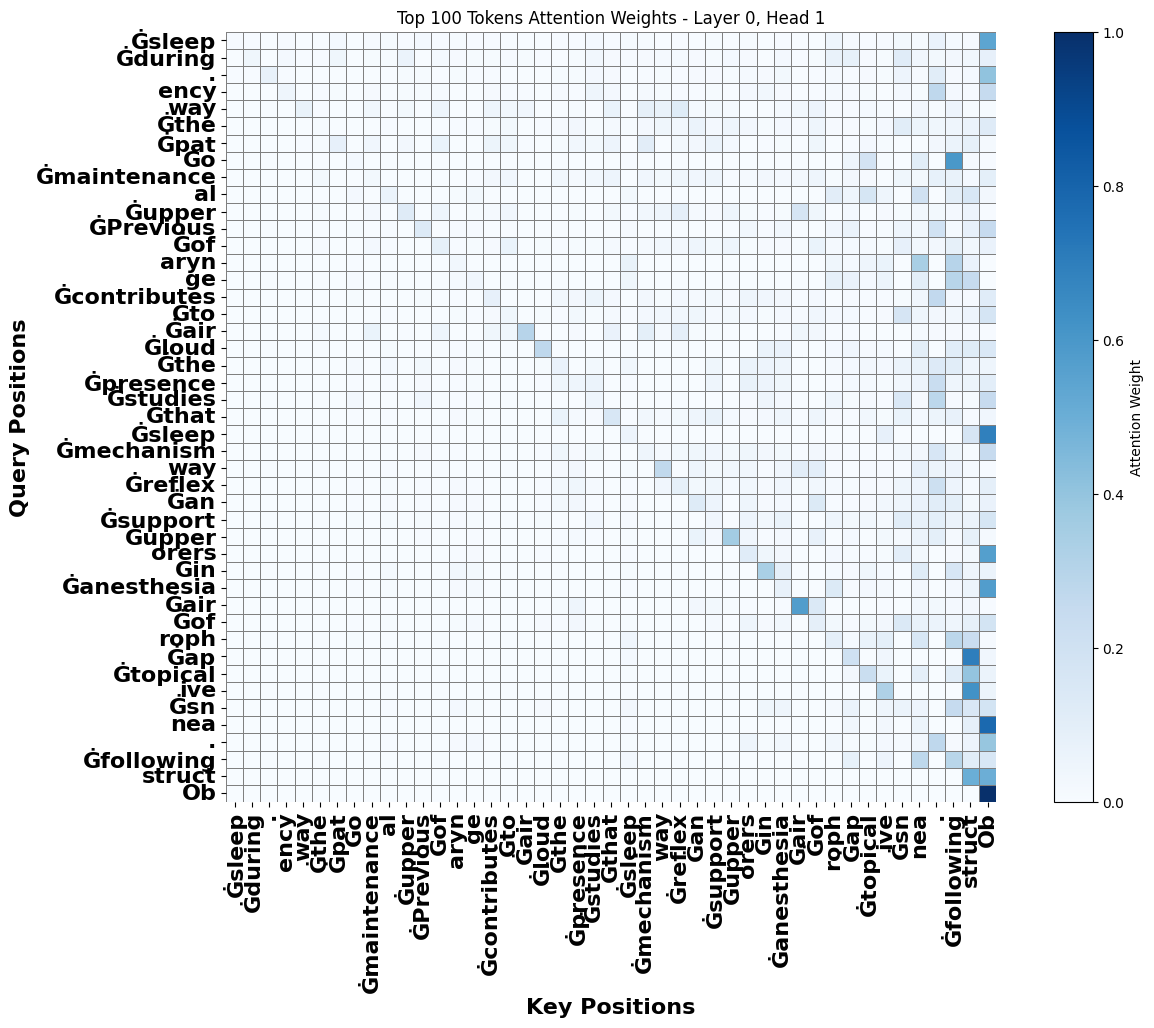

In [8]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def visualize_attention(model, tokenizer, text, layer_idx=-1, head_idx=0, top_n_tokens=150, filename="attention_heatmap.jpg"):
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()

    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512).to(device)

    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    attentions = outputs.attentions
    attention_matrix = attentions[layer_idx][0, head_idx].cpu().numpy()

    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    avg_attention = attention_matrix.mean(axis=0)
    top_indices = np.argsort(avg_attention)[-top_n_tokens:]
    top_tokens = [tokens[i] for i in top_indices]
    top_attention_matrix = attention_matrix[np.ix_(top_indices, top_indices)]
    df = pd.DataFrame(top_attention_matrix, index=top_tokens, columns=top_tokens)
    df.to_csv("fi_lora_dp_high_med_txt_gen_top_attention_matrix.csv")
    plt.figure(figsize=(15, 10))
    # Create the heatmap and store the result (QuadMesh object)
    heatmap = sns.heatmap(
        top_attention_matrix,
        cmap="Blues",
        linewidths=0.5,
        linecolor="gray",
        square=True,
        cbar=False,
        vmin=0, vmax=1,
        xticklabels=top_tokens, yticklabels=top_tokens
    )
    plt.xticks(rotation=90, fontsize=16, fontweight='bold')
    plt.yticks(fontsize=16, fontweight='bold')
    plt.xlabel("Key Positions", fontsize=16, fontweight='bold')
    plt.ylabel("Query Positions", fontsize=16, fontweight='bold')
    plt.title(f"Top {top_n_tokens} Tokens Attention Weights - Layer {layer_idx+1}, Head {head_idx+1}")
    plt.colorbar(heatmap.collections[0], label="Attention Weight") # Pass the QuadMesh object to colorbar

    plt.savefig(filename)
    plt.show()
text = "Obstructive sleep apnea following topical oropharyngeal anesthesia in loud snorers. Previous studies support the presence of an upper airway reflex mechanism that contributes to the maintenance of upper airway patency during sleep."
# Example usage
visualize_attention(generator_model, tokenizer, text, layer_idx=-1, head_idx=0, top_n_tokens=100, filename="fi_lora_dp_high_med_txt_gen_attn_map.jpg")


In [72]:
import numpy as np
import scipy.stats as stats
from sklearn.metrics.pairwise import cosine_similarity

def compute_spearman_correlation(shap_values, attention_weights):
    """Compute Spearman's rank correlation between SHAP values and attention weights."""
    spearman_corr, _ = stats.spearmanr(shap_values, attention_weights)
    return spearman_corr

# Ensure attention_matrix is converted to per-token weights
attention_weights = attention_matrix.mean(axis=0)  # Compute avg attention per token

# Ensure both lists are the same length
min_length = min(len(top_50_shap_values), len(attention_weights))
shap_values = top_50_shap_values[:min_length]
attention_weights = attention_weights[:min_length]

# Compute Metrics
spearman_corr = compute_spearman_correlation(shap_values, attention_weights)

# Print Results
print(f"Spearman Rank Correlation: {spearman_corr:.4f}")



Spearman Rank Correlation: 0.6411


In [86]:
common_tokens = set(top_50_tokens).intersection(set(top_tokens))

# Display the results
#print("Top 50 Tokens:", top_50_tokens)
#print("Another Token List:", top_tokens)
print("Common Tokens:", common_tokens)

Common Tokens: {'ym', 'Ġtopical', 'Ġ(', 'Ġage', 'pt', 'Ġanesthesia', 'Ġunderwent', 'Ġstudies', 'Ġmale', 'Ġupper', '.', 'Ġinvestigated', 'aryn', 'omatic', 'struct', 'Ġthree', 'Ġdevelopment', 'Ġone', 'ĠSEM', 'Ġobstruct', 'Ġto', 'ge', 'Ġthat', 'Ġof', 'al', 'Ġpossibility', 'Ġpresence', 'Ġyr', 'Ġon', 'Ġcontributes', 'Ġthe', 'Ġthis', 'orers', 'Ġas', 'way', 'Ġsuccessive', 'ive', 'Ġair', 'Ġsupport', 'Ġpat', 'Ġin', 'ĠPrevious', 'Ġreflex', 'seven', 'Ġloud', 'Ġ+/-', 'nea', 'Ġap', 'ency', 'Ġo', 'ĠWe', 'Ġovernight', 'Ġfemale', '),', 'Ġnights', 'Ġsleep', 'Ġsn', 'Ġ5', 'Ġfollowing', '3', 'ĠEight', 'Ġ39', 'Ġinterference', 'Ġotherwise', 'Ġduring', 'mean', 'Ġand', 'Ġmaintenance', 'Ġwith', 'Ġmechanism', 'roph', 'Ob', 'Ġan'}


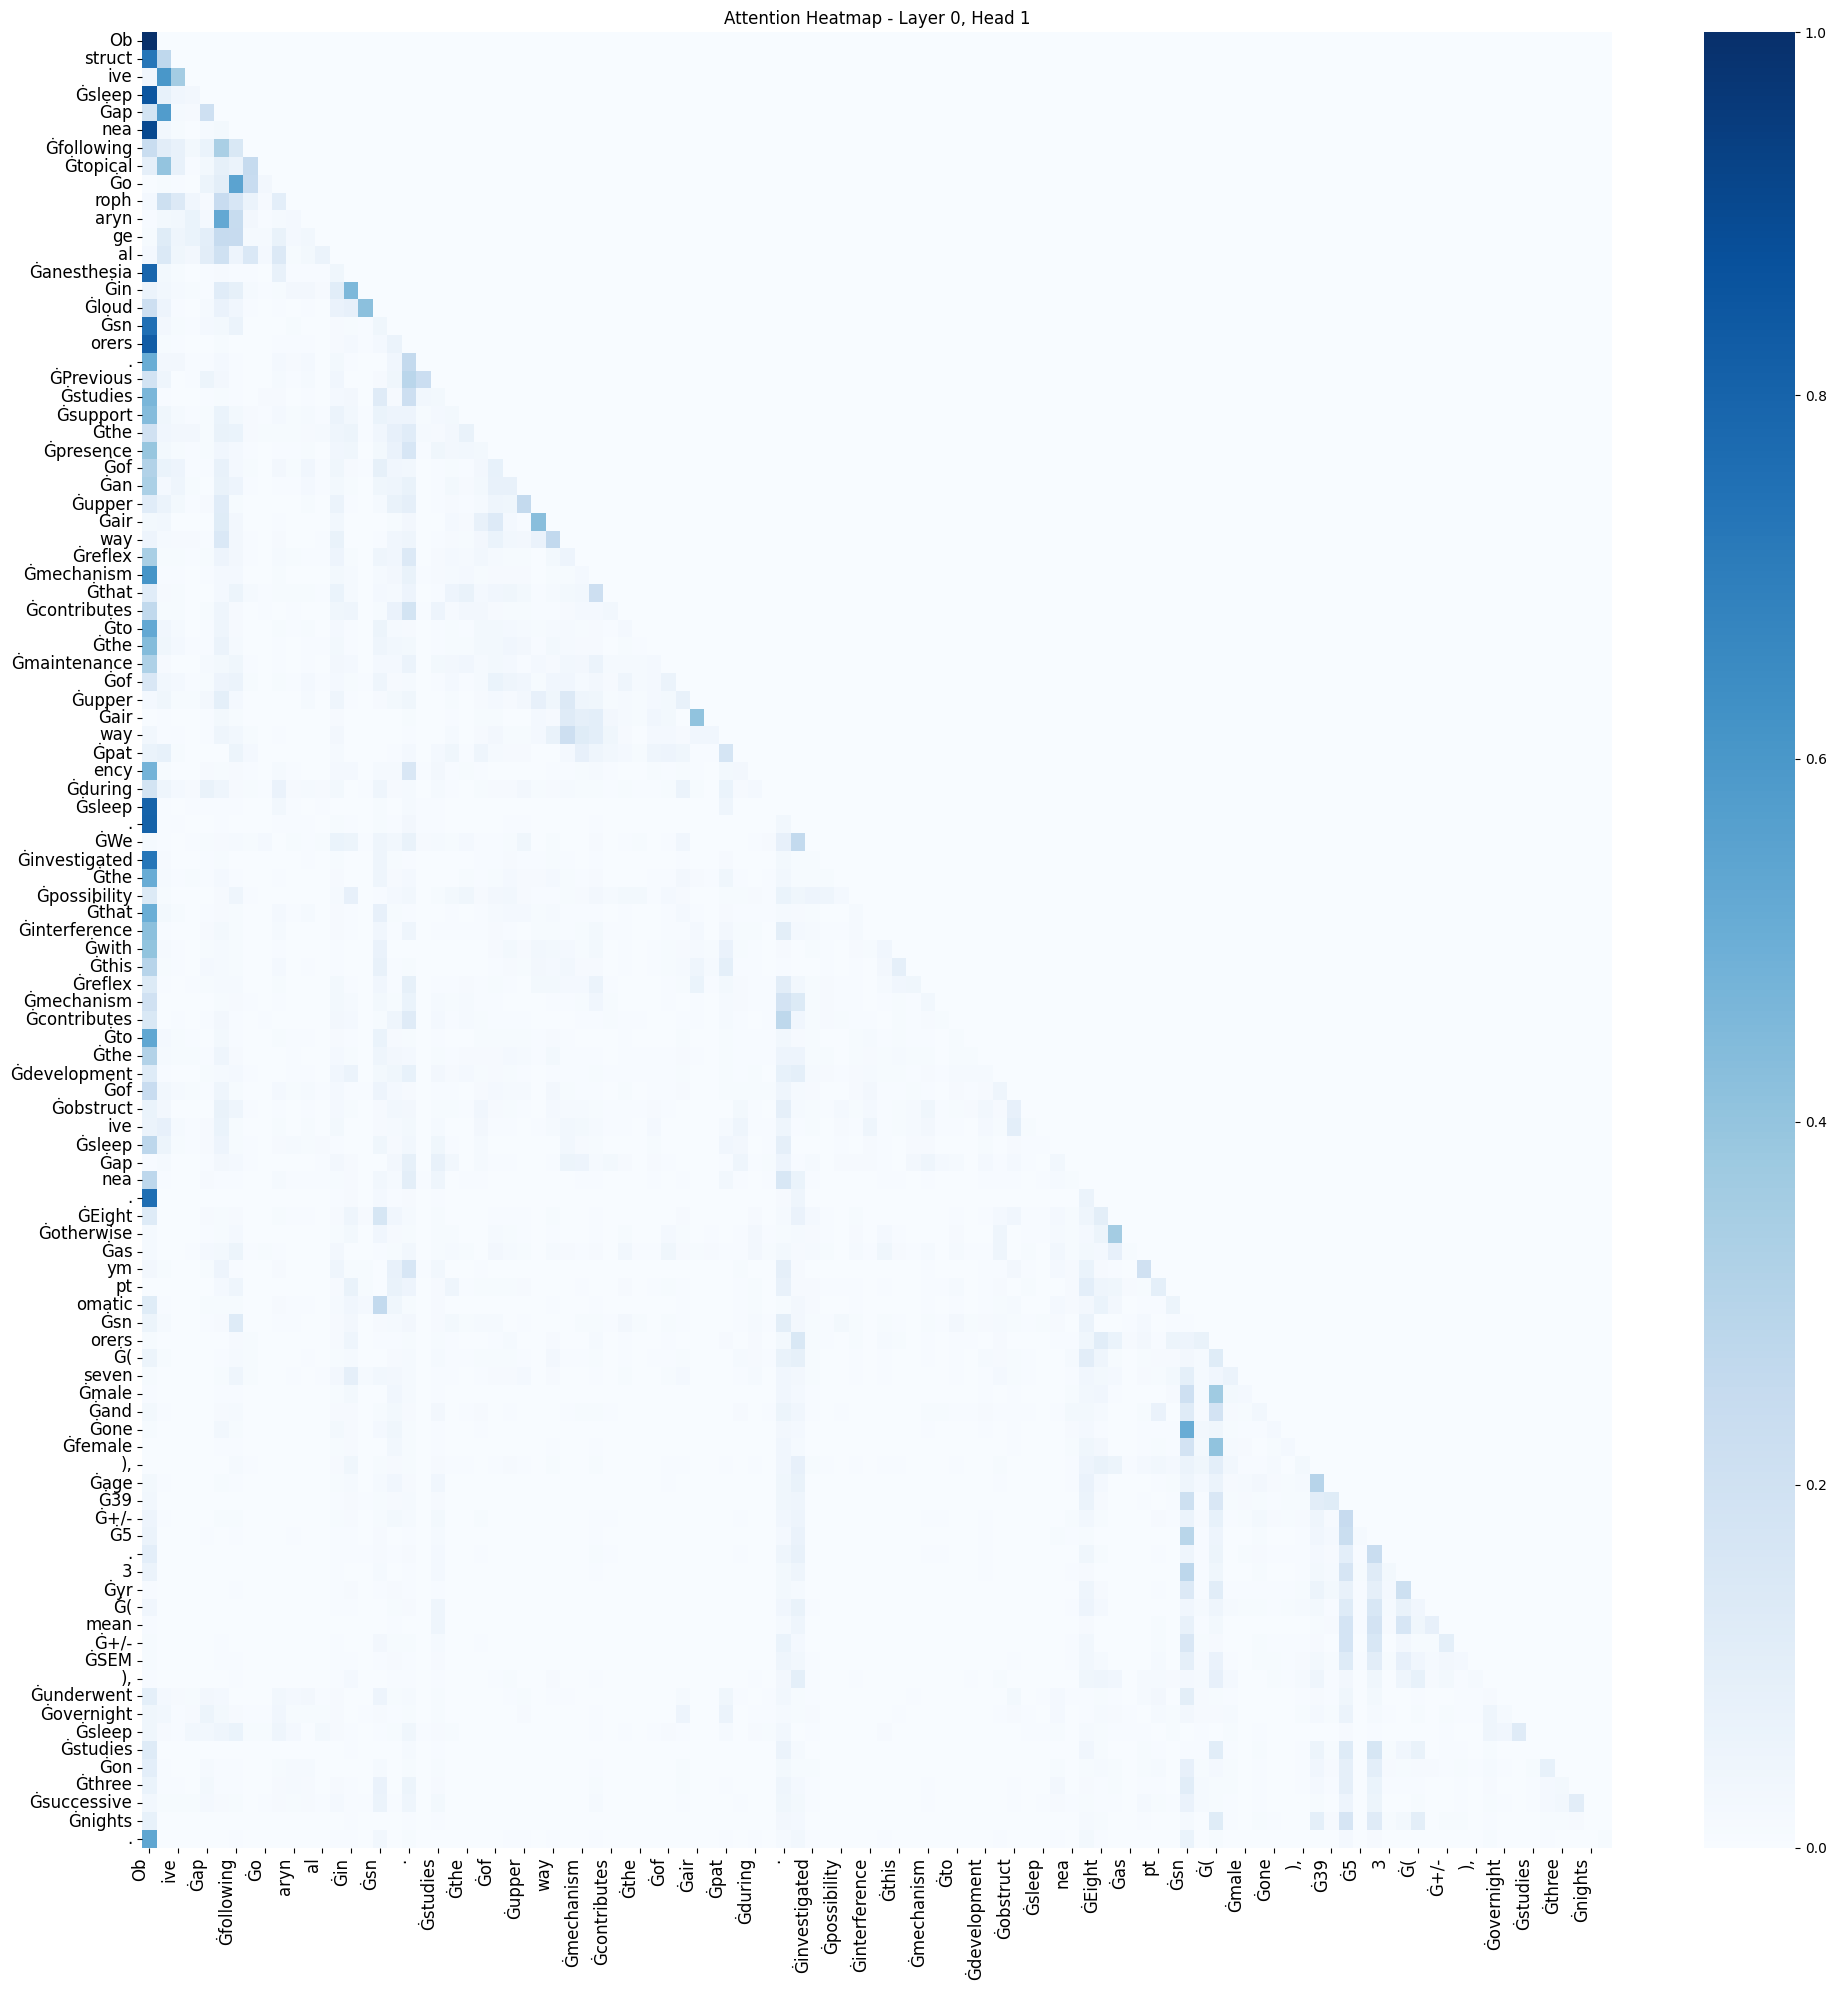

In [9]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd  # For better dataframe handling

# Input text
text = "Obstructive sleep apnea following topical oropharyngeal anesthesia in loud snorers. Previous studies support the presence of an upper airway reflex mechanism that contributes to the maintenance of upper airway patency during sleep. We investigated the possibility that interference with this reflex mechanism contributes to the development of obstructive sleep apnea. Eight otherwise asymptomatic snorers (seven male and one female), age 39 +/- 5.3 yr (mean +/- SEM), underwent overnight sleep studies on three successive nights."

# Device setup
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# Tokenize input
inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512).to(device)

# Forward pass (as before)
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# Extract attention matrices (layers, batch, heads, seq_len, seq_len)
attentions = outputs.attentions
layer_idx = -1  # Last layer
head_idx = 0    # First attention head

attention_matrix = attentions[layer_idx][0, head_idx].cpu().numpy()

# Retrieve tokens (subwords)
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

# 1. Word-Level Aggregation (if needed):
# (This part requires more advanced tokenization information if you want to 
#  perfectly align subwords to words.  A simplified version is shown below.)
word_tokens = []
word_attention = []
current_word = ""
current_attention = []

for i, token in enumerate(tokens):
    if token.startswith("##"):  # Simplified subword check (adjust as needed)
        current_word += token[2:]  # Remove "##"
        current_attention.append(attention_matrix[:, i])  # Collect attention for subword
    else:
        if current_word:  # Process previous word
            word_tokens.append(current_word)
            word_attention.append(np.mean(current_attention, axis=0)) # Average subword attn
        current_word = token
        current_attention = [attention_matrix[:, i]]

# Handle last word
if current_word:
    word_tokens.append(current_word)
    word_attention.append(np.mean(current_attention, axis=0))

word_attention_matrix = np.array(word_attention).T

# 2. Create DataFrame for Heatmap (improves labeling and readability):
df = pd.DataFrame(word_attention_matrix, index=word_tokens, columns=word_tokens)

# 3. Plot Heatmap:
plt.figure(figsize=(20, 20))  # Adjust size as needed
sns.heatmap(df, cmap="Blues", annot=False) # annot=True to see values (if manageable)
plt.xticks(rotation=90, ha="right", fontsize=12)  # Rotate and align x-axis labels
plt.yticks(rotation=0, fontsize=12)
plt.title(f"Attention Heatmap - Layer {layer_idx+1}, Head {head_idx+1}")
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.savefig('fi_attn_map.jpg')
plt.show()

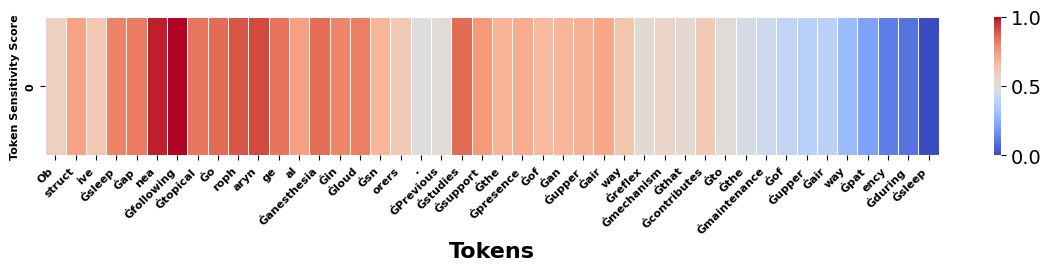

In [13]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
def compute_token_sensitivity(text):
    """Compute token sensitivity by measuring logit differences when modifying tokens."""
    tokens = tokenizer(text, return_tensors="pt", add_special_tokens=True).to("cuda")
    input_ids = tokens["input_ids"]

    with torch.no_grad():
        base_logits = generator_model(**tokens).logits[:, :-1, :]  # Exclude final token prediction

    sensitivities = []

    for i in range(input_ids.shape[1] - 1):  # Exclude last token
        perturbed_ids = input_ids.clone()
        perturbed_ids[:, i] = tokenizer.eos_token_id  # Use end-of-text token instead of MASK

        with torch.no_grad():
            perturbed_logits = generator_model(input_ids=perturbed_ids).logits[:, :-1, :]

        # Compute sensitivity as logit difference norm
        diff = torch.norm(base_logits - perturbed_logits, dim=-1).mean().item()
        sensitivities.append(diff)

    # Normalize scores to [0,1]
    sensitivities = np.array(sensitivities)
    sensitivities = (sensitivities - sensitivities.min()) / (sensitivities.max() - sensitivities.min() + 1e-8)

    return tokenizer.convert_ids_to_tokens(input_ids[0][:-1].tolist()), sensitivities

def plot_token_sensitivity(text, threshold_high=0.7, threshold_low=0.3):
    """
    Plot heatmap for token sensitivity visualization, highlighting high and low sensitivity tokens.

    Args:
        text: The input text string.
        threshold_high: Threshold for considering a token as having high sensitivity (between 0 and 1).
        threshold_low: Threshold for considering a token as having low sensitivity (between 0 and 1).
    """
    tokens, scores = compute_token_sensitivity(text)

    # Identify high and low sensitivity tokens
    high_sensitive_tokens = [
        (token, score) for token, score in zip(tokens, scores) if score >= threshold_high
    ]
    low_sensitive_tokens = [
        (token, score) for token, score in zip(tokens, scores) if score <= threshold_low
    ]

    # Print high and low sensitive tokens
    #print("High Sensitivity Tokens (Sensitivity >= {:.2f}):".format(threshold_high))
    #for token, score in high_sensitive_tokens:
    #    print(f"  {token}: {score:.2f}")

    #print("\nLow Sensitivity Tokens (Sensitivity <= {:.2f}):".format(threshold_low))
    #for token, score in low_sensitive_tokens:
    #    print(f"  {token}: {score:.2f}")

   # Create a list of labels for the heatmap
    labels =[]
    # Create a new list of scores, where intermediate sensitivity tokens are masked
    masked_scores =[]
    for i, score in enumerate(scores):
        if 0.3 <= score <= 1.0 or 0.0 <= score <= 0.3:
            masked_scores.append(score)
            labels.append(tokens[i])  # Keep the label for high/low sensitivity
        else:
            masked_scores.append(np.nan)  # Use NaN to mask intermediate values
            labels.append("")  # Empty string for intermediate sensitivity


    plt.figure(figsize=(12, 3))
    sns.heatmap([masked_scores], cmap="coolwarm", linewidths=0.5, cbar=True,
                mask=np.isnan([masked_scores]))  # Use mask to hide NaN cells
    plt.xticks(ticks=np.arange(len(tokens)) + 0.5, labels=labels, rotation=45, ha="right", fontweight="bold", fontsize=8)
    plt.xlabel("Tokens",fontweight="bold",fontsize=16)
    plt.yticks(fontweight="bold",fontsize=8)
    plt.ylabel("Token Sensitivity Score",fontweight="bold",fontsize=8)
    plt.title("")
    plt.tight_layout()
    plt.savefig('fi_lora_dp_high_med_txt_gen_tkn_smap.jpg')
    plt.show()
text = "Obstructive sleep apnea following topical oropharyngeal anesthesia in loud snorers. Previous studies support the presence of an upper airway reflex mechanism that contributes to the maintenance of upper airway patency during sleep."
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
generator_model.to(device)
generator_model.eval()
plot_token_sensitivity(text)

In [9]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cosine

# Load attention matrices from CSV files
lora_matrix = pd.read_csv("lora_med_txt_gen_top_attention_matrix.csv", index_col=0).values
lora_dp_matrix = pd.read_csv("lora_dp_med_txt_gen_top_attention_matrix.csv", index_col=0).values
fi_lora_dp_matrix = pd.read_csv("fi_lora_dp_high_med_txt_gen_top_attention_matrix.csv", index_col=0).values

# Flatten matrices into 1D vectors
lora_vec = lora_matrix.flatten()
lora_dp_vec = lora_dp_matrix.flatten()
fi_lora_dp_vec = fi_lora_dp_matrix.flatten()

# Compute cosine similarity
cosine_sim_lora_vs_lora_dp = 1 - cosine(lora_vec, lora_dp_vec)
cosine_sim_lora_vs_fi_lora_dp = 1 - cosine(lora_vec, fi_lora_dp_vec)

# Print results
print(f"Cosine Similarity (LoRA vs. LoRA + Gaussian DP): {cosine_sim_lora_vs_lora_dp:.4f}")
print(f"Cosine Similarity (LoRA vs. LoRA + Feature Importance Adaptive Noise): {cosine_sim_lora_vs_fi_lora_dp:.4f}")


Cosine Similarity (LoRA vs. LoRA + Gaussian DP): 0.4899
Cosine Similarity (LoRA vs. LoRA + Feature Importance Adaptive Noise): 0.5062


C:\Users\my pc\AppData\Local\Temp\ipykernel_16348\2024318931.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")


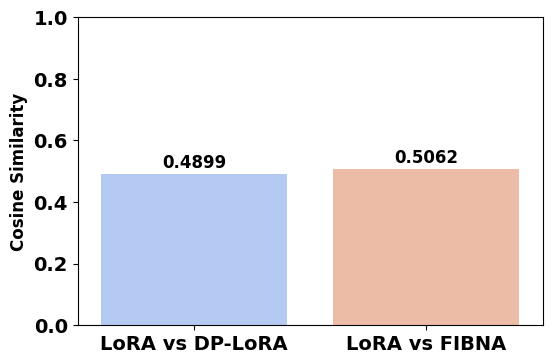

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Load attention weight matrices
attn_lora = pd.read_csv("lora_med_txt_gen_top_attention_matrix.csv", index_col=0).values  
attn_dp = pd.read_csv("lora_dp_med_txt_gen_top_attention_matrix.csv", index_col=0).values  
attn_fi_lora_dp = pd.read_csv("fi_lora_dp_high_med_txt_gen_top_attention_matrix.csv", index_col=0).values  

# Flatten matrices for cosine similarity computation
vec_lora = attn_lora.flatten().reshape(1, -1)
vec_dp = attn_dp.flatten().reshape(1, -1)
vec_fi_lora_dp = attn_fi_lora_dp.flatten().reshape(1, -1)

# Compute cosine similarities with LoRA fine-tuning as the baseline
cos_sim_dp = cosine_similarity(vec_lora, vec_dp)[0][0]
cos_sim_fi_lora_dp = cosine_similarity(vec_lora, vec_fi_lora_dp)[0][0]

# Create DataFrame for visualization
df_sim = pd.DataFrame({
    "Method": ["LoRA vs DP-LoRA", "LoRA vs FIBNA"],
    "Cosine Similarity": [cos_sim_dp, cos_sim_fi_lora_dp]
})

# ---- Visualization ----
plt.figure(figsize=(6, 4))
sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")
plt.ylim(0, 1)  # Cosine similarity range
plt.ylabel("Cosine Similarity", fontsize=12, fontweight="bold")
plt.xlabel("",fontsize=14, fontweight="bold")
plt.title("", fontsize=14, fontweight="bold")
plt.xticks(fontsize=14, fontweight="bold")
plt.yticks(fontsize=14, fontweight="bold")

# Annotate bars with similarity values
for index, row in df_sim.iterrows():
    plt.text(index, row["Cosine Similarity"] + 0.02, f"{row['Cosine Similarity']:.4f}", ha='center', fontsize=12, fontweight="bold")

# Save & Show Plot
plt.savefig("med_txt_gen_cosine_similarity_comparison.jpg", dpi=300, bbox_inches="tight")
plt.show()


C:\Users\my pc\AppData\Local\Temp\ipykernel_16348\1383428902.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")


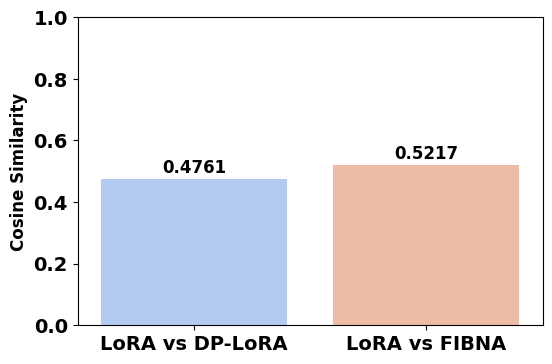

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Load attention weight matrices
attn_lora = pd.read_csv("lora_medal_txt_gen_top_attention_matrix.csv", index_col=0).values  
attn_dp = pd.read_csv("lora_dp_medal_txt_gen_top_attention_matrix.csv", index_col=0).values  
attn_fi_lora_dp = pd.read_csv("fi_lora_dp_high_medal_txt_gen_top_attention_matrix.csv", index_col=0).values  

# Flatten matrices for cosine similarity computation
vec_lora = attn_lora.flatten().reshape(1, -1)
vec_dp = attn_dp.flatten().reshape(1, -1)
vec_fi_lora_dp = attn_fi_lora_dp.flatten().reshape(1, -1)

# Compute cosine similarities with LoRA fine-tuning as the baseline
cos_sim_dp = cosine_similarity(vec_lora, vec_dp)[0][0]
cos_sim_fi_lora_dp = cosine_similarity(vec_lora, vec_fi_lora_dp)[0][0]

# Create DataFrame for visualization
df_sim = pd.DataFrame({
    "Method": ["LoRA vs DP-LoRA", "LoRA vs FIBNA"],
    "Cosine Similarity": [cos_sim_dp, cos_sim_fi_lora_dp]
})

# ---- Visualization ----
plt.figure(figsize=(6, 4))
sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")
plt.ylim(0, 1)  # Cosine similarity range
plt.ylabel("Cosine Similarity", fontsize=12, fontweight="bold")
plt.xlabel("",fontsize=14, fontweight="bold")
plt.title("", fontsize=14, fontweight="bold")
plt.xticks(fontsize=14, fontweight="bold")
plt.yticks(fontsize=14, fontweight="bold")

# Annotate bars with similarity values
for index, row in df_sim.iterrows():
    plt.text(index, row["Cosine Similarity"] + 0.02, f"{row['Cosine Similarity']:.4f}", ha='center', fontsize=12, fontweight="bold")

# Save & Show Plot
plt.savefig("medal_txt_gen_cosine_similarity_comparison.jpg", dpi=300, bbox_inches="tight")
plt.show()


C:\Users\my pc\AppData\Local\Temp\ipykernel_16348\2220830352.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")


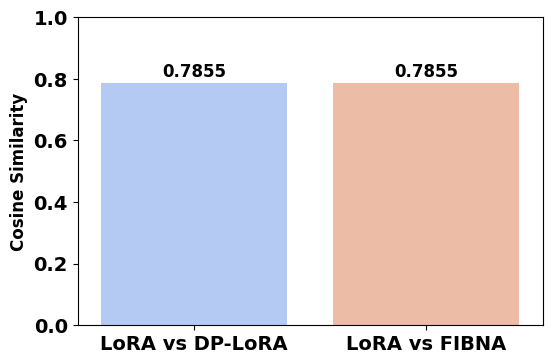

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Load attention weight matrices
attn_lora = pd.read_csv("lora_medal_txt_llm32_top_attention_matrix.csv", index_col=0).values  
attn_dp = pd.read_csv("lora_dp_high_medal_txt_llm32_top_attention_matrix.csv", index_col=0).values  
attn_fi_lora_dp = pd.read_csv("fi_lora_dp_high_medal_txt_llm32_top_attention_matrix.csv", index_col=0).values  

# Flatten matrices for cosine similarity computation
vec_lora = attn_lora.flatten().reshape(1, -1)
vec_dp = attn_dp.flatten().reshape(1, -1)
vec_fi_lora_dp = attn_fi_lora_dp.flatten().reshape(1, -1)

# Compute cosine similarities with LoRA fine-tuning as the baseline
cos_sim_dp = cosine_similarity(vec_lora, vec_dp)[0][0]
cos_sim_fi_lora_dp = cosine_similarity(vec_lora, vec_fi_lora_dp)[0][0]

# Create DataFrame for visualization
df_sim = pd.DataFrame({
    "Method": ["LoRA vs DP-LoRA", "LoRA vs FIBNA"],
    "Cosine Similarity": [cos_sim_dp, cos_sim_fi_lora_dp]
})

# ---- Visualization ----
plt.figure(figsize=(6, 4))
sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")
plt.ylim(0, 1)  # Cosine similarity range
plt.ylabel("Cosine Similarity", fontsize=12, fontweight="bold")
plt.xlabel("",fontsize=14, fontweight="bold")
plt.title("", fontsize=14, fontweight="bold")
plt.xticks(fontsize=14, fontweight="bold")
plt.yticks(fontsize=14, fontweight="bold")

# Annotate bars with similarity values
for index, row in df_sim.iterrows():
    plt.text(index, row["Cosine Similarity"] + 0.02, f"{row['Cosine Similarity']:.4f}", ha='center', fontsize=12, fontweight="bold")

# Save & Show Plot
plt.savefig("medal_txt_llm32_cosine_similarity_comparison.jpg", dpi=300, bbox_inches="tight")
plt.show()


C:\Users\my pc\AppData\Local\Temp\ipykernel_16348\843156019.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")


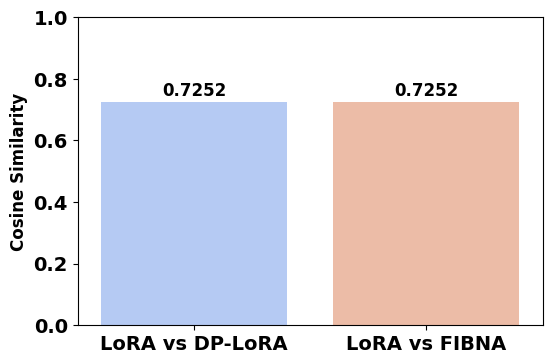

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Load attention weight matrices
attn_lora = pd.read_csv("lora_med_txt_llm32_top_attention_matrix.csv", index_col=0).values  
attn_dp = pd.read_csv("lora_dp_med_txt_llm32_top_attention_matrix.csv", index_col=0).values  
attn_fi_lora_dp = pd.read_csv("fi_lora_dp_med_txt_llm32_top_attention_matrix.csv", index_col=0).values  

# Flatten matrices for cosine similarity computation
vec_lora = attn_lora.flatten().reshape(1, -1)
vec_dp = attn_dp.flatten().reshape(1, -1)
vec_fi_lora_dp = attn_fi_lora_dp.flatten().reshape(1, -1)

# Compute cosine similarities with LoRA fine-tuning as the baseline
cos_sim_dp = cosine_similarity(vec_lora, vec_dp)[0][0]
cos_sim_fi_lora_dp = cosine_similarity(vec_lora, vec_fi_lora_dp)[0][0]

# Create DataFrame for visualization
df_sim = pd.DataFrame({
    "Method": ["LoRA vs DP-LoRA", "LoRA vs FIBNA"],
    "Cosine Similarity": [cos_sim_dp, cos_sim_fi_lora_dp]
})

# ---- Visualization ----
plt.figure(figsize=(6, 4))
sns.barplot(x="Method", y="Cosine Similarity", data=df_sim, palette="coolwarm")
plt.ylim(0, 1)  # Cosine similarity range
plt.ylabel("Cosine Similarity", fontsize=12, fontweight="bold")
plt.xlabel("",fontsize=14, fontweight="bold")
plt.title("", fontsize=14, fontweight="bold")
plt.xticks(fontsize=14, fontweight="bold")
plt.yticks(fontsize=14, fontweight="bold")

# Annotate bars with similarity values
for index, row in df_sim.iterrows():
    plt.text(index, row["Cosine Similarity"] + 0.02, f"{row['Cosine Similarity']:.4f}", ha='center', fontsize=12, fontweight="bold")

# Save & Show Plot
plt.savefig("med_txt_llm32_cosine_similarity_comparison.jpg", dpi=300, bbox_inches="tight")
plt.show()


In [16]:
!pip install umap-learn

Silhouette Score: -0.0419
Davies-Bouldin Index: 18.4564
Calinski-Harabasz Index: 1.1005


C:\Users\my pc\.ai-navigator\micromamba\envs\cuda\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


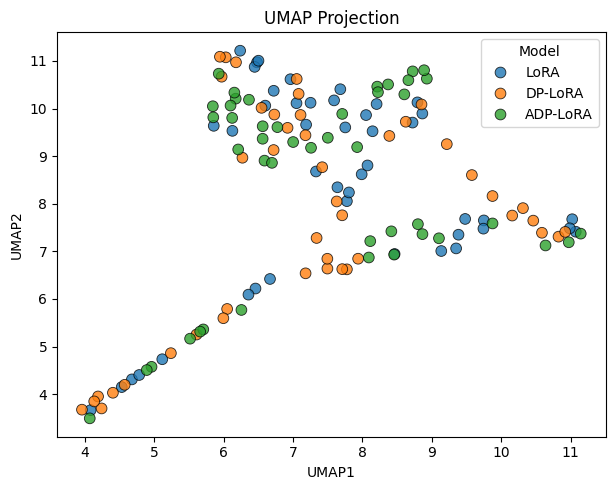

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Load attention matrices
attn_lora = pd.read_csv("lora_med_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_dp_lora = pd.read_csv("lora_dp_med_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_adp_lora = pd.read_csv("fi_lora_dp_high_med_txt_gen_top_attention_matrix.csv", index_col=0).values

# Ensure proper shape
num_tokens, attn_dim = attn_lora.shape  # Assuming (tokens, attention dim)

# Combine matrices correctly
X = np.vstack([attn_lora, attn_dp_lora, attn_adp_lora])  # Shape: (3*num_tokens, attn_dim)
# Correct labels
labels = (["LoRA"] * num_tokens) + (["DP-LoRA"] * num_tokens) + (["ADP-LoRA"] * num_tokens)
# Encode labels for metric computation
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels)
# Apply UMAP
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X)

df_umap = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
df_umap["Model"] = labels
# Compute cluster quality metrics
silhouette = silhouette_score(X_umap, encoded_labels)
davies_bouldin = davies_bouldin_score(X_umap, encoded_labels)
calinski_harabasz = calinski_harabasz_score(X_umap, encoded_labels)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
# Plot all three methods
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 3)
sns.scatterplot(x="UMAP1", y="UMAP2", hue="Model", data=df_umap, palette="tab10", alpha=0.8, s=60, edgecolor="black")
plt.title("UMAP Projection")

plt.tight_layout()
plt.show()


C:\Users\my pc\.ai-navigator\micromamba\envs\cuda\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Score: 0.0121
Davies-Bouldin Index: 3.6171
Calinski-Harabasz Index: 17.3263


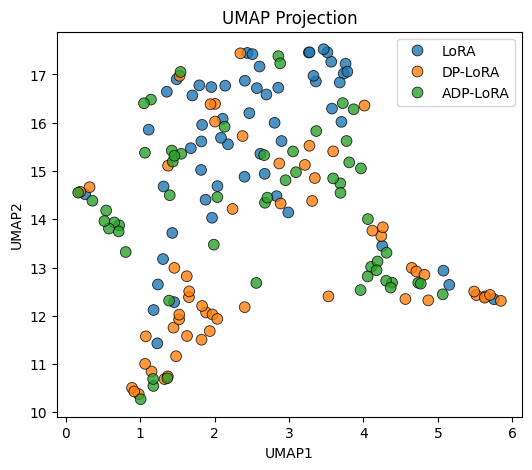

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.preprocessing import LabelEncoder

# Load attention matrices
attn_lora = pd.read_csv("lora_medal_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_dp_lora = pd.read_csv("lora_dp_medal_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_adp_lora = pd.read_csv("fi_lora_dp_high_medal_txt_gen_top_attention_matrix.csv", index_col=0).values

# Ensure proper shape
num_tokens, attn_dim = attn_lora.shape  # Assuming (tokens, attention dim)

# Combine matrices correctly
X = np.vstack([attn_lora, attn_dp_lora, attn_adp_lora])  # Shape: (3*num_tokens, attn_dim)
labels = (['LoRA'] * num_tokens) + (['DP-LoRA'] * num_tokens) + (['ADP-LoRA'] * num_tokens)

# Encode labels for metric computation
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels)

# Apply UMAP
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X)

df_umap = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
df_umap["Model"] = labels

# Compute cluster quality metrics
silhouette = silhouette_score(X_umap, encoded_labels)
davies_bouldin = davies_bouldin_score(X_umap, encoded_labels)
calinski_harabasz = calinski_harabasz_score(X_umap, encoded_labels)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")

# Plot UMAP projection
plt.figure(figsize=(6, 5))
sns.scatterplot(x="UMAP1", y="UMAP2", hue="Model", data=df_umap, palette="tab10", alpha=0.8, s=60, edgecolor="black")
plt.title("UMAP Projection")
plt.legend()
plt.show()

In [24]:
import numpy as np
import pandas as pd
import umap
from scipy.spatial.distance import euclidean
from scipy.stats import wasserstein_distance
from sklearn.metrics import pairwise_distances

# Load attention matrices
attn_lora = pd.read_csv("lora_medal_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_dp_lora = pd.read_csv("lora_dp_medal_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_adp_lora = pd.read_csv("fi_lora_dp_high_medal_txt_gen_top_attention_matrix.csv", index_col=0).values

# Combine matrices
num_tokens, attn_dim = attn_lora.shape  # (tokens, attention_dim)
X = np.vstack([attn_lora, attn_dp_lora, attn_adp_lora])
labels = (["LoRA"] * num_tokens) + (["DP-LoRA"] * num_tokens) + (["ADP-LoRA"] * num_tokens)

# Apply UMAP for dimensionality reduction
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X)

# Split UMAP embeddings by method
X_lora = X_umap[:num_tokens]
X_dp_lora = X_umap[num_tokens:2*num_tokens]
X_adp_lora = X_umap[2*num_tokens:]

# Compute centroids
centroid_lora = np.mean(X_lora, axis=0)
centroid_dp_lora = np.mean(X_dp_lora, axis=0)
centroid_adp_lora = np.mean(X_adp_lora, axis=0)

# Compute pairwise centroid distances
dist_lora_dp_lora = euclidean(centroid_lora, centroid_dp_lora)
dist_lora_adp_lora = euclidean(centroid_lora, centroid_adp_lora)
dist_dp_lora_adp_lora = euclidean(centroid_dp_lora, centroid_adp_lora)

# Compute Wasserstein distances
wasserstein_lora_dp_lora = wasserstein_distance(X_lora[:, 0], X_dp_lora[:, 0]) + wasserstein_distance(X_lora[:, 1], X_dp_lora[:, 1])
wasserstein_lora_adp_lora = wasserstein_distance(X_lora[:, 0], X_adp_lora[:, 0]) + wasserstein_distance(X_lora[:, 1], X_adp_lora[:, 1])
wasserstein_dp_lora_adp_lora = wasserstein_distance(X_dp_lora[:, 0], X_adp_lora[:, 0]) + wasserstein_distance(X_dp_lora[:, 1], X_adp_lora[:, 1])

# Compute average pairwise Euclidean distances
avg_dist_lora_dp_lora = np.mean(pairwise_distances(X_lora, X_dp_lora))
avg_dist_lora_adp_lora = np.mean(pairwise_distances(X_lora, X_adp_lora))
avg_dist_dp_lora_adp_lora = np.mean(pairwise_distances(X_dp_lora, X_adp_lora))

# Return all computed distances
{
    "Centroid Distances": {
        "LoRA vs DP-LoRA": dist_lora_dp_lora,
        "LoRA vs ADP-LoRA": dist_lora_adp_lora,
        "DP-LoRA vs ADP-LoRA": dist_dp_lora_adp_lora
    },
    "Wasserstein Distances": {
        "LoRA vs DP-LoRA": wasserstein_lora_dp_lora,
        "LoRA vs ADP-LoRA": wasserstein_lora_adp_lora,
        "DP-LoRA vs ADP-LoRA": wasserstein_dp_lora_adp_lora
    },
    "Average Pairwise Euclidean Distances": {
        "LoRA vs DP-LoRA": avg_dist_lora_dp_lora,
        "LoRA vs ADP-LoRA": avg_dist_lora_adp_lora,
        "DP-LoRA vs ADP-LoRA": avg_dist_dp_lora_adp_lora
    }
}


C:\Users\my pc\.ai-navigator\micromamba\envs\cuda\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


{'Centroid Distances': {'LoRA vs DP-LoRA': 2.4166042804718018,
  'LoRA vs ADP-LoRA': 1.3824318647384644,
  'DP-LoRA vs ADP-LoRA': 1.0417991876602173},
 'Wasserstein Distances': {'LoRA vs DP-LoRA': 2.883819898492411,
  'LoRA vs ADP-LoRA': 1.8732633747552572,
  'DP-LoRA vs ADP-LoRA': 1.467579429086886},
 'Average Pairwise Euclidean Distances': {'LoRA vs DP-LoRA': 3.5398545,
  'LoRA vs ADP-LoRA': 2.8819666,
  'DP-LoRA vs ADP-LoRA': 3.063707}}

In [25]:
import numpy as np
import pandas as pd
import umap
from scipy.spatial.distance import euclidean
from scipy.stats import wasserstein_distance
from sklearn.metrics import pairwise_distances

# Load attention matrices
attn_lora = pd.read_csv("lora_med_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_dp_lora = pd.read_csv("lora_dp_med_txt_gen_top_attention_matrix.csv", index_col=0).values
attn_adp_lora = pd.read_csv("fi_lora_dp_high_med_txt_gen_top_attention_matrix.csv", index_col=0).values

# Combine matrices
num_tokens, attn_dim = attn_lora.shape  # (tokens, attention_dim)
X = np.vstack([attn_lora, attn_dp_lora, attn_adp_lora])
labels = (["LoRA"] * num_tokens) + (["DP-LoRA"] * num_tokens) + (["ADP-LoRA"] * num_tokens)

# Apply UMAP for dimensionality reduction
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X)

# Split UMAP embeddings by method
X_lora = X_umap[:num_tokens]
X_dp_lora = X_umap[num_tokens:2*num_tokens]
X_adp_lora = X_umap[2*num_tokens:]

# Compute centroids
centroid_lora = np.mean(X_lora, axis=0)
centroid_dp_lora = np.mean(X_dp_lora, axis=0)
centroid_adp_lora = np.mean(X_adp_lora, axis=0)

# Compute pairwise centroid distances
dist_lora_dp_lora = euclidean(centroid_lora, centroid_dp_lora)
dist_lora_adp_lora = euclidean(centroid_lora, centroid_adp_lora)
dist_dp_lora_adp_lora = euclidean(centroid_dp_lora, centroid_adp_lora)

# Compute Wasserstein distances
wasserstein_lora_dp_lora = wasserstein_distance(X_lora[:, 0], X_dp_lora[:, 0]) + wasserstein_distance(X_lora[:, 1], X_dp_lora[:, 1])
wasserstein_lora_adp_lora = wasserstein_distance(X_lora[:, 0], X_adp_lora[:, 0]) + wasserstein_distance(X_lora[:, 1], X_adp_lora[:, 1])
wasserstein_dp_lora_adp_lora = wasserstein_distance(X_dp_lora[:, 0], X_adp_lora[:, 0]) + wasserstein_distance(X_dp_lora[:, 1], X_adp_lora[:, 1])

# Compute average pairwise Euclidean distances
avg_dist_lora_dp_lora = np.mean(pairwise_distances(X_lora, X_dp_lora))
avg_dist_lora_adp_lora = np.mean(pairwise_distances(X_lora, X_adp_lora))
avg_dist_dp_lora_adp_lora = np.mean(pairwise_distances(X_dp_lora, X_adp_lora))

# Return all computed distances
{
    "Centroid Distances": {
        "LoRA vs DP-LoRA": dist_lora_dp_lora,
        "LoRA vs ADP-LoRA": dist_lora_adp_lora,
        "DP-LoRA vs ADP-LoRA": dist_dp_lora_adp_lora
    },
    "Wasserstein Distances": {
        "LoRA vs DP-LoRA": wasserstein_lora_dp_lora,
        "LoRA vs ADP-LoRA": wasserstein_lora_adp_lora,
        "DP-LoRA vs ADP-LoRA": wasserstein_dp_lora_adp_lora
    },
    "Average Pairwise Euclidean Distances": {
        "LoRA vs DP-LoRA": avg_dist_lora_dp_lora,
        "LoRA vs ADP-LoRA": avg_dist_lora_adp_lora,
        "DP-LoRA vs ADP-LoRA": avg_dist_dp_lora_adp_lora
    }
}


C:\Users\my pc\.ai-navigator\micromamba\envs\cuda\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


{'Centroid Distances': {'LoRA vs DP-LoRA': 0.7067870497703552,
  'LoRA vs ADP-LoRA': 0.18860378861427307,
  'DP-LoRA vs ADP-LoRA': 0.744795560836792},
 'Wasserstein Distances': {'LoRA vs DP-LoRA': 1.0637770652770997,
  'LoRA vs ADP-LoRA': 0.5751372125413683,
  'DP-LoRA vs ADP-LoRA': 1.2179534488254122},
 'Average Pairwise Euclidean Distances': {'LoRA vs DP-LoRA': 3.4159513,
  'LoRA vs ADP-LoRA': 3.147013,
  'DP-LoRA vs ADP-LoRA': 3.4156392}}

C:\Users\my pc\AppData\Local\Temp\ipykernel_21428\3650589529.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(distances.keys()), y=list(distances.values()), palette="coolwarm")


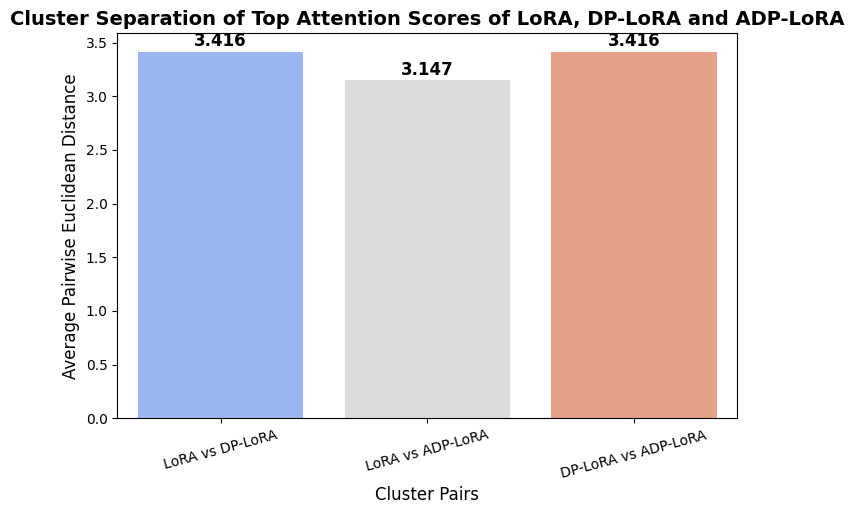

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Average pairwise Euclidean distances
distances = {
    "LoRA vs DP-LoRA": 3.4159513,
    "LoRA vs ADP-LoRA": 3.147013,
    "DP-LoRA vs ADP-LoRA": 3.4156392
}

# Create a bar plot
plt.figure(figsize=(8, 5))
sns.barplot(x=list(distances.keys()), y=list(distances.values()), palette="coolwarm")

# Labels and title
plt.ylabel("Average Pairwise Euclidean Distance", fontsize=12)
plt.xlabel("Cluster Pairs", fontsize=12)
plt.title("Cluster Separation of Top Attention Scores of LoRA, DP-LoRA and ADP-LoRA", fontsize=14, fontweight="bold")
plt.xticks(rotation=15)

# Show values on bars
for i, v in enumerate(distances.values()):
    plt.text(i, v + 0.05, f"{v:.3f}", ha='center', fontsize=12, fontweight="bold")

plt.show()


C:\Users\my pc\AppData\Local\Temp\ipykernel_21428\2083484988.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(distances.keys()), y=list(distances.values()), palette="coolwarm")


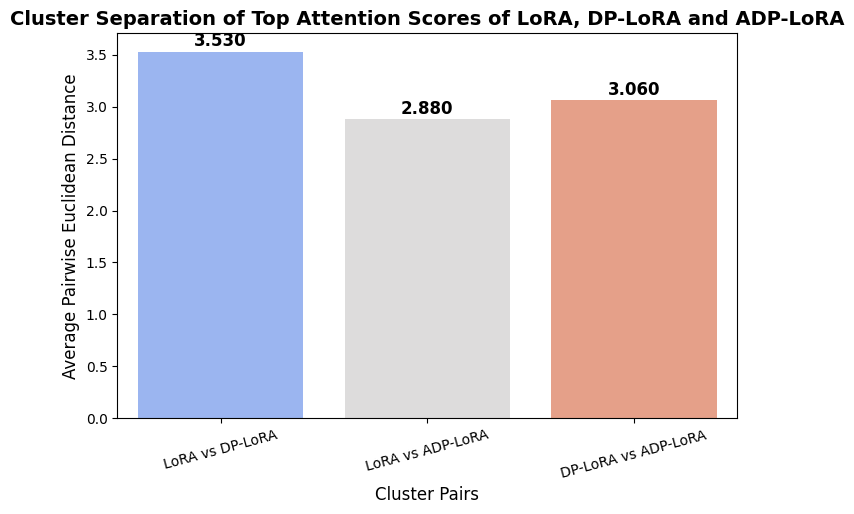

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Average pairwise Euclidean distances
distances = {
    "LoRA vs DP-LoRA": 3.53,
    "LoRA vs ADP-LoRA": 2.88,
    "DP-LoRA vs ADP-LoRA": 3.06
}

# Create a bar plot
plt.figure(figsize=(8, 5))
sns.barplot(x=list(distances.keys()), y=list(distances.values()), palette="coolwarm")

# Labels and title
plt.ylabel("Average Pairwise Euclidean Distance", fontsize=12)
plt.xlabel("Cluster Pairs", fontsize=12)
plt.title("Cluster Separation of Top Attention Scores of LoRA, DP-LoRA and ADP-LoRA", fontsize=14, fontweight="bold")
plt.xticks(rotation=15)

# Show values on bars
for i, v in enumerate(distances.values()):
    plt.text(i, v + 0.05, f"{v:.3f}", ha='center', fontsize=12, fontweight="bold")

plt.show()


In [16]:
import torch
import torch.nn.functional as F
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
#	Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent. The aseptically loosened prosthesis provided a means for investigating the in vivo and in vitro activity of the cells associated with the loosening process in seven dogs. The cells were isolated and maintained in culture for sufficient periods of time so that their biologic activity could be studied as well as the effect of different agents added to the cells in vivo or in vitro. The biologic response as determined by interleukin-1 and prostaglandin E2 activity paralleled the roentgenographic appearance of loosening and the technetium images and observations made at the time of revision surgery. The correlation between clinical, roentgenographic, histologic, and biochemical loosening indicates that the canine model is suitable for investigating the mechanisms of prosthetic failure. A canine model permits the study of possible nonsurgical therapeutic interventions with the ultimate hope of stopping or slowing the loosening process. 
# Training Text
training_text = "Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent."
# Generate synthetic text
input_ids = tokenizer(training_text, return_tensors="pt").input_ids.to(device)
output_ids = generator_model.generate(input_ids, max_length=200, pad_token_id=tokenizer.eos_token_id)
generated_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print("tarining:",training_text)
print("generated:",generated_text)


tarining: Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent.
generated: Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent.

The study was funded by the National Institutes of Health (grant R01 AI087692).

Source: University of California, San Francisco

Explore further: New study shows how prosthetic limbs can be damaged by bacteria


tarining: Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent.
generated:  agent.

The study was funded by the National Institutes of Health (grant R01 AI087692).

Source: University of California, San Francisco

Explore further: New study shows how prosthetic limbs can be damaged by bacteria


C:\Users\my pc\AppData\Local\Temp\ipykernel_16464\340841687.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=train_tokens, y=train_entropy, palette=colors_train, ax=axes[0])
C:\Users\my pc\AppData\Local\Temp\ipykernel_16464\340841687.py:39: UserWarning: The palette list has more values (21) than needed (20), which may not be intended.
  sns.barplot(x=train_tokens, y=train_entropy, palette=colors_train, ax=axes[0])
C:\Users\my pc\AppData\Local\Temp\ipykernel_16464\340841687.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(train_tokens, rotation=90)
C:\Users\my pc\AppData\Local\Temp\ipykernel_16464\340841687.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assig

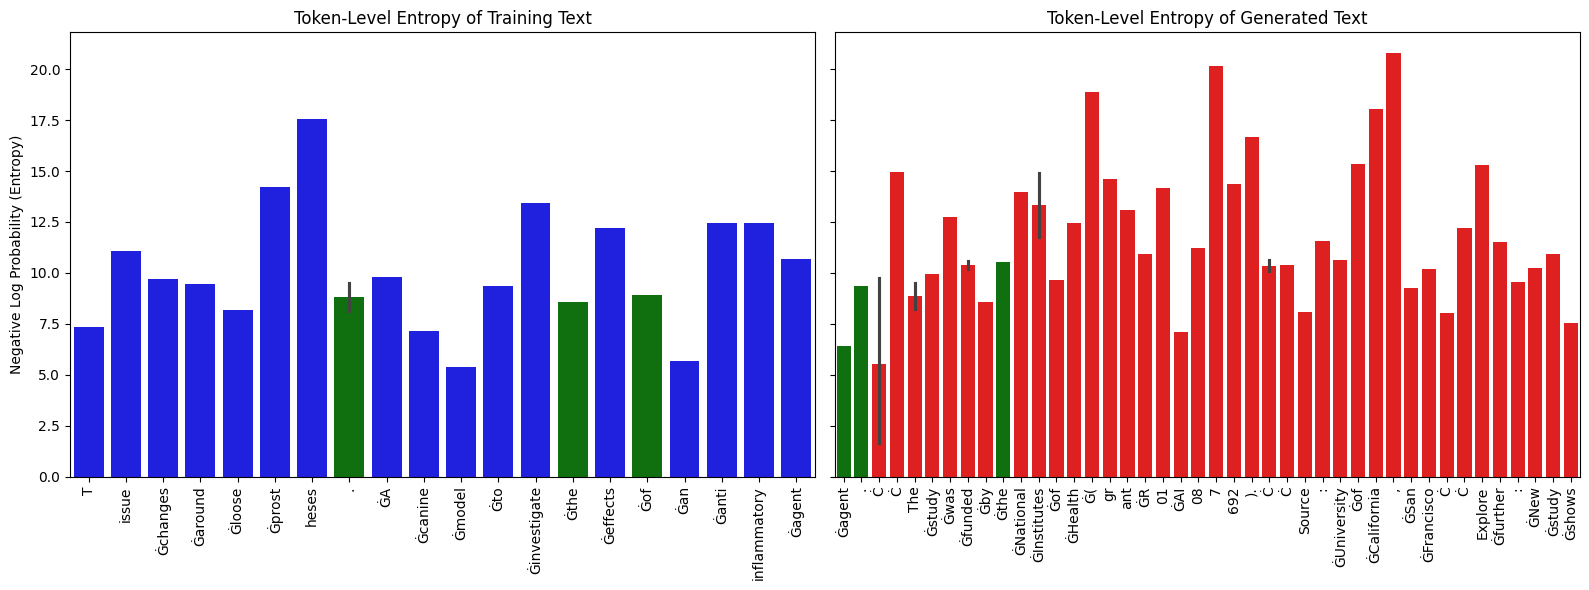

In [17]:
# Tokenize texts
train_tokens = tokenizer.tokenize(training_text)
gen_tokens = tokenizer.tokenize(generated_text)
# Make sure train and gen texts have similar lengths before encoding
train_tokens = train_tokens[:min(len(train_tokens), len(gen_tokens))]
gen_tokens = gen_tokens[19:len(gen_tokens)]

# Convert back to string and encode again
training_text = tokenizer.convert_tokens_to_string(train_tokens)
generated_text = tokenizer.convert_tokens_to_string(gen_tokens)
# Function to compute token probabilities
def get_token_probabilities(text, model, tokenizer):
    input_ids = tokenizer(text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
    logits = outputs.logits
    probs = F.softmax(logits, dim=-1)
    token_probs = [probs[0, i, token_id].item() for i, token_id in enumerate(input_ids[0])]
    return token_probs, tokenizer.convert_ids_to_tokens(input_ids[0])
print("tarining:",training_text)
print("generated:",generated_text)
# Compute token probabilities and entropy
train_probs, _ = get_token_probabilities(training_text, generator_model, tokenizer)
gen_probs, _ = get_token_probabilities(generated_text, generator_model, tokenizer)
train_entropy = [-np.log(p) for p in train_probs]
gen_entropy = [-np.log(p) for p in gen_probs]

# Identify memorized tokens (common in both texts & entropy < threshold)
threshold = 10  # Adjust threshold as needed
memorized_tokens = set(train_tokens) & set(gen_tokens)
memorized_indices_train = [i for i, token in enumerate(train_tokens) if token in memorized_tokens and train_entropy[i] < threshold]
memorized_indices_gen = [i for i, token in enumerate(gen_tokens) if token in memorized_tokens and gen_entropy[i] < threshold]

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Training Text Plot
colors_train = ['green' if i in memorized_indices_train else 'blue' for i in range(len(train_tokens))]
sns.barplot(x=train_tokens, y=train_entropy, palette=colors_train, ax=axes[0])
axes[0].set_title("Token-Level Entropy of Training Text")
axes[0].set_ylabel("Negative Log Probability (Entropy)")
axes[0].set_xticklabels(train_tokens, rotation=90)

# Generated Text Plot
colors_gen = ['green' if i in memorized_indices_gen else 'red' for i in range(len(gen_tokens))]
sns.barplot(x=gen_tokens, y=gen_entropy, palette=colors_gen, ax=axes[1])
axes[1].set_title("Token-Level Entropy of Generated Text")
axes[1].set_xticklabels(gen_tokens, rotation=90)

plt.tight_layout()
plt.savefig('fi_lora_dp_high_med_txt_gen_tkn_mem.jpg')
plt.show()


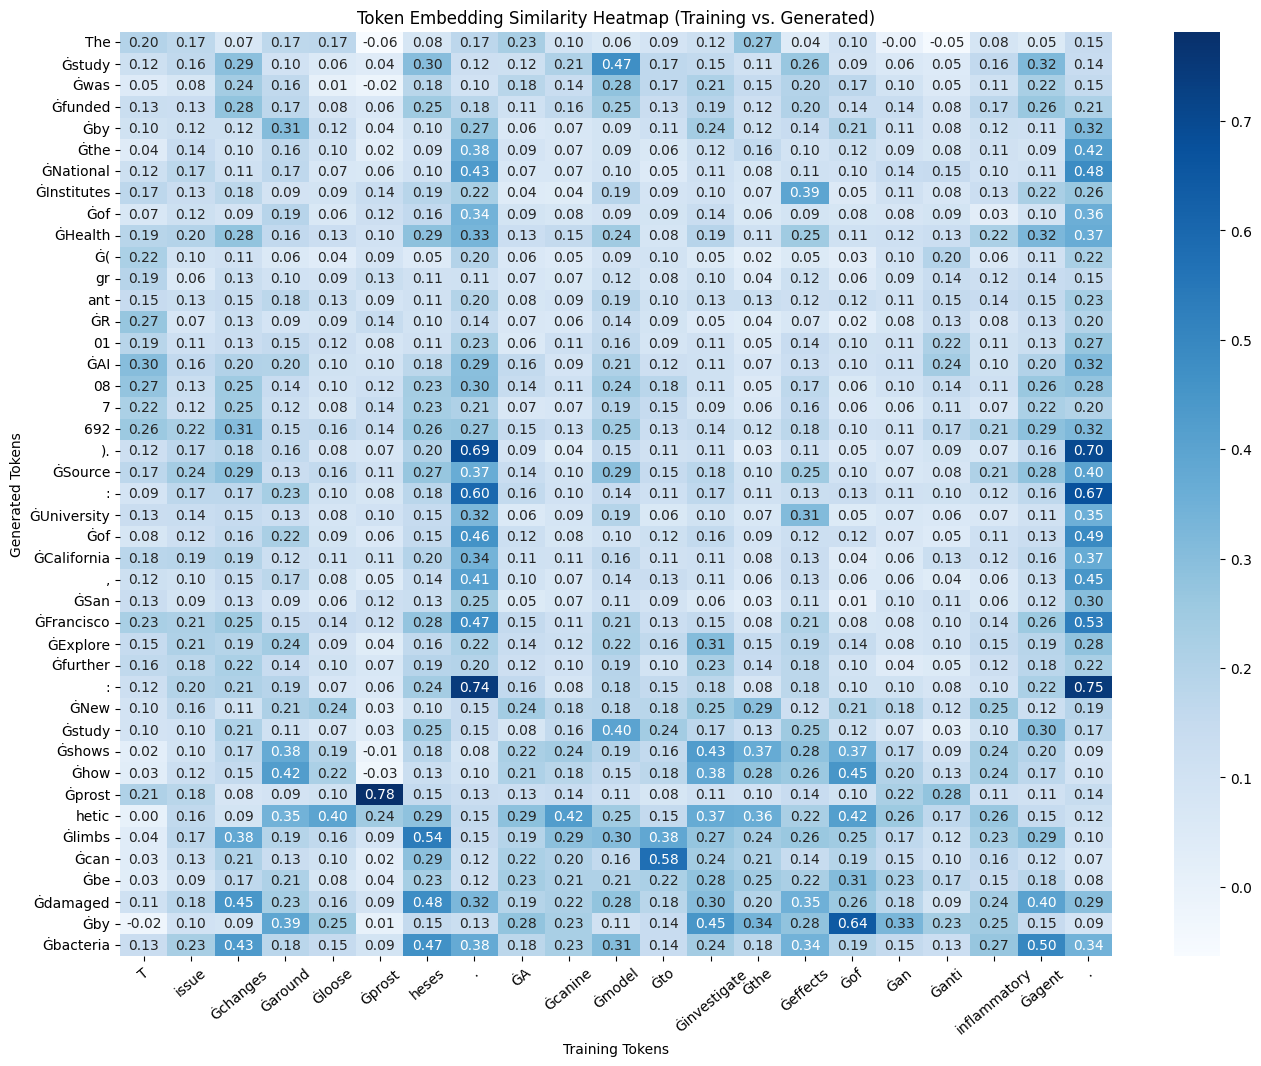

In [9]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModel
generator_model.to(device)
# Example Training & Generated Texts
training_text = "Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent."
generated_text = "The study was funded by the National Institutes of Health (grant R01 AI087692). Source: University of California, San Francisco Explore further: New study shows how prosthetic limbs can be damaged by bacteria"

train_tokens = tokenizer.tokenize(training_text)
gen_tokens = tokenizer.tokenize(generated_text)

# Function to Get Token Embeddings
def get_token_embeddings(tokens):
    input_ids = tokenizer.convert_tokens_to_ids(tokens)
    input_tensor = torch.tensor([input_ids]).to(device)  # Move to GPU if available

    with torch.no_grad():
        outputs = generator_model(input_tensor, output_hidden_states=True)  # Get hidden states
        hidden_states = outputs.hidden_states[-1]  # Extract last layer hidden states
    
    return hidden_states.squeeze(0).cpu().numpy()  # Convert to numpy


# Compute Token Embeddings
train_embeddings = get_token_embeddings(train_tokens)
gen_embeddings = get_token_embeddings(gen_tokens)

# Compute Cosine Similarity Matrix
similarity_matrix = cosine_similarity(gen_embeddings, train_embeddings)

# Plot Heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(similarity_matrix, annot=True, cmap="Blues", xticklabels=train_tokens, yticklabels=gen_tokens, fmt=".2f")

plt.xlabel("Training Tokens")
plt.ylabel("Generated Tokens")
plt.title("Token Embedding Similarity Heatmap (Training vs. Generated)")
plt.xticks(rotation=40)
plt.yticks(rotation=0)
plt.savefig('fi_lora_dp_high_med_txt_gen_tkn_similarity.jpg')
plt.show()


In [1]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, GenerationConfig

train_df = pd.read_csv("medical_tc_train.csv")
texts = train_df["medical_abstract"][:100].tolist()

BASE_MODEL = "gpt2-large"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CONTEXT_LENGTHS     = [30, 35, 40, 45, 50, 55]
CONTINUATION_LENGTHS = [30, 25, 20, 15, 10, 5]

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def greedy_generate_ids(model, prompt_ids, K):
    inp = torch.tensor(prompt_ids).unsqueeze(0).to(DEVICE)
    cfg = GenerationConfig(
        max_new_tokens=K,
        do_sample=False,
        temperature=1.0,
        top_k=0,
        top_p=1.0,
        pad_token_id=tokenizer.eos_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    with torch.no_grad():
        out = model.generate(input_ids=inp, generation_config=cfg)
    return out[0].tolist()[len(prompt_ids):len(prompt_ids)+K]

def M_theta(decoded, gold):
    return sum(int(d==g) for d,g in zip(decoded, gold)) / len(gold)


In [2]:
def load_model(model,filename='fi_lora_dp_high_med_txt_gen.pth'):
    # Load the state_dict from the saved file
    checkpoint = torch.load(filename)
    epoch = checkpoint['epoch']
    model.resize_token_embeddings(len(tokenizer))
    model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    print(f"Model loaded from {filename}")
    return model, epoch
model = AutoModelForCausalLM.from_pretrained("gpt2-large").to("cuda" if torch.cuda.is_available() else "cpu")
generator_model, start_epoch = load_model(model)

print("Generator model loaded successfully!")

generator_model.to(DEVICE).eval()

DEBUG = True     # set False for full runs
DEBUG_SAMPLES = 100   # only debug first 2 texts to avoid spam

rows = []

for C,K in zip(CONTEXT_LENGTHS, CONTINUATION_LENGTHS):
    scores = []

    print(f"\n=== C={C}, K={K} ===")

    for idx, text in enumerate(texts):
        tok = tokenizer.encode(text, add_special_tokens=False)
        if len(tok) < C+K:
            continue

        prefix = tok[:C]
        gold   = tok[C:C+K]

        pred = greedy_generate_ids(generator_model, prefix, K)

        score = M_theta(pred, gold)
        scores.append(score)

        # if DEBUG and idx < DEBUG_SAMPLES:
        #     print(f"\n--- Sample {idx} ---")
        #     print(f"prefix ids      : {prefix}")
        #     print(f"gold ids        : {gold}")
        #     print(f"generated ids   : {pred}")
        #     print(f"match mask      : {[int(p==g) for p,g in zip(pred,gold)]}")
        #     print(f"M_theta         : {score:.4f}")

    rows.append({"Context":C, "Continuation":K, "FIBNA":sum(scores)/len(scores)})

df_fibna = pd.DataFrame(rows).round(4)
df_fibna


C:\Users\my pc\AppData\Local\Temp\ipykernel_19912\2262184596.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(filename)
The following generation f

Model loaded from fi_lora_dp_high_med_txt_gen.pth
Generator model loaded successfully!

=== C=30, K=30 ===

=== C=35, K=25 ===

=== C=40, K=20 ===

=== C=45, K=15 ===

=== C=50, K=10 ===

=== C=55, K=5 ===


,Context,Continuation,FIBNA
0,30,30,0.0540
1,35,25,0.0656
2,40,20,0.0720
3,45,15,0.1120
4,50,10,0.1440
5,55,5,0.2600


In [3]:
def load_model(model,filename='lora_dp_medical_gpt2.pth'):
    # Load the state_dict from the saved file
    checkpoint = torch.load(filename)
    epoch = checkpoint['epoch']
    model.resize_token_embeddings(len(tokenizer))
    model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    print(f"Model loaded from {filename}")
    return model, epoch
tokenizer = AutoTokenizer.from_pretrained("./lora_dp_medical_gpt2")
model = AutoModelForCausalLM.from_pretrained("./lora_dp_medical_gpt2").to("cuda" if torch.cuda.is_available() else "cpu")

generator_model, start_epoch = load_model(model)

print("Generator model loaded successfully!")

generator_model.to(DEVICE).eval()

DEBUG = True     # set False for full runs
DEBUG_SAMPLES = 100   # only debug first 2 texts to avoid spam

rows = []

for C,K in zip(CONTEXT_LENGTHS, CONTINUATION_LENGTHS):
    scores = []

    print(f"\n=== C={C}, K={K} ===")

    for idx, text in enumerate(texts):
        tok = tokenizer.encode(text, add_special_tokens=False)
        if len(tok) < C+K:
            continue

        prefix = tok[:C]
        gold   = tok[C:C+K]

        pred = greedy_generate_ids(generator_model, prefix, K)

        score = M_theta(pred, gold)
        scores.append(score)

        # if DEBUG and idx < DEBUG_SAMPLES:
        #     print(f"\n--- Sample {idx} ---")
        #     print(f"prefix ids      : {prefix}")
        #     print(f"gold ids        : {gold}")
        #     print(f"generated ids   : {pred}")
        #     print(f"match mask      : {[int(p==g) for p,g in zip(pred,gold)]}")
        #     print(f"M_theta         : {score:.4f}")

    rows.append({"Context":C, "Continuation":K, "FIBNA":sum(scores)/len(scores)})

df_dplora = pd.DataFrame(rows).round(4)
df_dplora


C:\Users\my pc\AppData\Local\Temp\ipykernel_19912\3639865399.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(filename)


Model loaded from lora_dp_medical_gpt2.pth
Generator model loaded successfully!

=== C=30, K=30 ===

=== C=35, K=25 ===

=== C=40, K=20 ===

=== C=45, K=15 ===

=== C=50, K=10 ===

=== C=55, K=5 ===


,Context,Continuation,FIBNA
0,30,30,0.0593
1,35,25,0.0656
2,40,20,0.0845
3,45,15,0.1187
4,50,10,0.1530
5,55,5,0.2680


In [4]:
# Load the LoRA fine-tuned model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("./lora_medical_gpt2")
generator_model = AutoModelForCausalLM.from_pretrained("./lora_medical_gpt2").to("cuda")
rows = []

for C,K in zip(CONTEXT_LENGTHS, CONTINUATION_LENGTHS):
    scores = []
    for text in texts:
        tok = tokenizer.encode(text, add_special_tokens=False)
        if len(tok) < C+K:
            continue
        prefix = tok[:C]
        gold   = tok[C:C+K]
        pred = greedy_generate_ids(generator_model, prefix, K)
        scores.append(M_theta(pred, gold))
    rows.append({"Context":C, "Continuation":K, "LoRA":sum(scores)/len(scores)})

df_lora = pd.DataFrame(rows).round(4)
df_lora


,Context,Continuation,LoRA
0,30,30,0.0703
1,35,25,0.0712
2,40,20,0.0840
3,45,15,0.1227
4,50,10,0.1560
5,55,5,0.2980
